### Proyecto Despliegue Soluciones Analiticas

Presentado por:
- Laura Marcela Ramirez Casallas
- Kevin Alejandro Caicedo Rodriguez
- Jhon Jairo Meneses Prieto
- Jeferson Andrés Gutiérrez Gutiérrez

## Pregunta de Negocio


El examen **saber 11°** es una prueba utilizada por el instituto colombiano para la evaluación de la Educación (ICFES)1, para realizar mediciones oficiales acerca de la calidad del servicio educativo prestado a nivel nacional. Esta prueba es practicada a los estudiantes de todos los establecimientos educativos, privados y públicos, que están terminando su formación académica media (grado 11, previo a iniciar la formación universitaria). 

Con este contexto, el problema que vamos a abordar se enfoca en entender cuáles son los factores o variables que inciden en los resultados obtenidos por cada estudiante con el fin de enfocar el uso de los recursos disponibles para implementar políticas públicas que busquen fortalecer las competencias de los estudiantes del país. 

Por tal razón, bajo este contexto, la pregunta de negocio es la siguiente:

#### *¿Cómo puede la secretaria de educacion lograr el aumento de la aprobación del ICFES mediante el análisis de variables demográficas, socioeconómicos e institucionales para identificar brechas de rendimiento y mejorar la calidad educativa de cada una de las instituciones analizadas de la ciudad de Bogotá?*

## Fuente de los datos

Para dar solución al caso de estudio contamos con los datos publicados a través de la plataforma de Datos Abiertos de Colombia, a los que se puede acceder a través del siguiente URL: 

https://www.datos.gov.co/en/Educaci-n/Bogota_historico_saber_11/8qwp-pzhz/about_data

## Importación de Datos

In [2]:
pip install Sodapy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Vamos a utilizar el año 2022, que es el mas reciente y el que surge luego de pandemia

In [2]:
from sodapy import Socrata
import pandas as pd

APP_TOKEN = "zkj4BAQIZkr7n4t4NKzvLt5zq"
client = Socrata("datos.gov.co", APP_TOKEN, timeout=120)

dataset_id = "8qwp-pzhz"
periodo_objetivo = 20224

limit = 50000
offset = 0
all_results = []

while True:
    results = client.get(
        dataset_id,
        where=f"periodo = '{periodo_objetivo}'",
        order="estu_consecutivo ASC",
        limit=limit,
        offset=offset
    )

    if not results:
        break

    all_results.extend(results)
    offset += len(results)

    print(f"Descargados {len(all_results)} registros...")

df = pd.DataFrame.from_records(all_results)

print("Total de registros:", len(df))
print("Filas completamente duplicadas:", df.duplicated().sum())
print("Identificadores únicos:", df["estu_consecutivo"].nunique())

Descargados 50000 registros...
Descargados 100000 registros...
Descargados 150000 registros...
Descargados 152584 registros...
Total de registros: 152584
Filas completamente duplicadas: 76331
Identificadores únicos: 76253


In [4]:
print(f"Registros: {df.shape[0]:,}")
print(f"Variables: {df.shape[1]}")
display(df.head())

Registros: 152,584
Variables: 51


,periodo,estu_tipodocumento,estu_consecutivo,cole_area_ubicacion,cole_bilingue,cole_calendario,cole_caracter,cole_cod_dane_establecimiento,cole_cod_dane_sede,cole_cod_depto_ubicacion,...,fami_tienecomputador,fami_tieneinternet,fami_tienelavadora,desemp_ingles,punt_ingles,punt_matematicas,punt_sociales_ciudadanas,punt_c_naturales,punt_lectura_critica,punt_global
0,20224,TI,SB11202240002331,URBANO,N,A,ACADÉMICO,111001014176,111001014176,11,...,Si,Si,Si,A1,56,51,52,46,59,262
1,20224,TI,SB11202240002331,URBANO,N,A,ACADÉMICO,111001014176,111001014176,11,...,Si,Si,Si,A1,56,51,52,46,59,262
2,20224,TI,SB11202240002335,URBANO,N,A,ACADÉMICO,111001014176,111001014176,11,...,No,No,Si,A1,48,51,49,46,45,239
3,20224,TI,SB11202240002335,URBANO,N,A,ACADÉMICO,111001014176,111001014176,11,...,No,No,Si,A1,48,51,49,46,45,239
4,20224,TI,SB11202240002340,URBANO,N,A,ACADÉMICO,111001076376,111001076376,11,...,No,No,Si,A-,42,45,34,39,55,216


In [5]:
display(df.info())
display(df.describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 152584 entries, 0 to 152583
Data columns (total 51 columns):
 #   Column                         Non-Null Count   Dtype
---  ------                         --------------   -----
 0   periodo                        152584 non-null  str  
 1   estu_tipodocumento             152584 non-null  str  
 2   estu_consecutivo               152584 non-null  str  
 3   cole_area_ubicacion            152584 non-null  str  
 4   cole_bilingue                  124416 non-null  str  
 5   cole_calendario                152584 non-null  str  
 6   cole_caracter                  145548 non-null  str  
 7   cole_cod_dane_establecimiento  152584 non-null  str  
 8   cole_cod_dane_sede             152584 non-null  str  
 9   cole_cod_depto_ubicacion       152584 non-null  str  
 10  cole_cod_mcpio_ubicacion       152584 non-null  str  
 11  cole_codigo_icfes              152584 non-null  str  
 12  cole_depto_ubicacion           152584 non-null  str  
 13  cole_gener

None

,count,unique,top,freq
periodo,152584,1,20224,152584
estu_tipodocumento,152584,11,TI,131232
estu_consecutivo,152584,76253,SB11202240071420,4
cole_area_ubicacion,152584,2,URBANO,151258
cole_bilingue,124416,2,N,123762
cole_calendario,152584,3,A,151360
cole_caracter,145548,4,ACADÉMICO,124824
cole_cod_dane_establecimiento,152584,1131,111001024732,852
cole_cod_dane_sede,152584,1143,111001024732,852
cole_cod_depto_ubicacion,152584,1,11,152584


# Diagnósitico de calidad de datos

### Nulos x columnas

In [6]:
resumen_nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje_nulos": (df.isna().mean() * 100).round(2)
})

resumen_nulos = resumen_nulos.query("nulos > 0")
resumen_nulos = resumen_nulos.sort_values(
    "porcentaje_nulos",
    ascending=False
)

display(resumen_nulos)

,nulos,porcentaje_nulos
cole_bilingue,28168,18.46
cole_caracter,7036,4.61
fami_estratovivienda,6514,4.27
fami_tieneinternet,6200,4.06
fami_educacionpadre,6108,4.00
fami_educacionmadre,6088,3.99
fami_tieneautomovil,4346,2.85
fami_cuartoshogar,4330,2.84
fami_tienelavadora,4182,2.74
fami_tienecomputador,4130,2.71


### Duplicidad

In [7]:
print('Filas duplicadas: ', df.duplicated().sum())
print("Duplicados por estudiante:",df["estu_consecutivo"].duplicated().sum())

Filas duplicadas:  76331
Duplicados por estudiante: 76331


In [8]:
# ver estudiantes que mas se repiten
df["estu_consecutivo"].value_counts().loc[lambda x: x > 1]

estu_consecutivo
SB11202240071420    4
SB11202240071460    4
SB11202240071555    4
SB11202240071605    4
SB11202240071678    4
                   ..
SB11202240616298    2
SB11202240616299    2
SB11202240616309    2
SB11202240616360    2
SB11202240616361    2
Name: count, Length: 76253, dtype: int64

In [9]:
pd.set_option('display.max_columns', None)

df_duplicados = df[
    df.duplicated(keep=False)
]

display(df_duplicados[df_duplicados['estu_consecutivo']=='SB11202240072129'])

,periodo,estu_tipodocumento,estu_consecutivo,cole_area_ubicacion,cole_bilingue,cole_calendario,cole_caracter,cole_cod_dane_establecimiento,cole_cod_dane_sede,cole_cod_depto_ubicacion,cole_cod_mcpio_ubicacion,cole_codigo_icfes,cole_depto_ubicacion,cole_genero,cole_jornada,cole_mcpio_ubicacion,cole_naturaleza,cole_nombre_establecimiento,cole_nombre_sede,cole_sede_principal,estu_cod_depto_presentacion,estu_cod_mcpio_presentacion,estu_cod_reside_depto,estu_cod_reside_mcpio,estu_depto_presentacion,estu_depto_reside,estu_estadoinvestigacion,estu_estudiante,estu_fechanacimiento,estu_genero,estu_mcpio_presentacion,estu_mcpio_reside,estu_nacionalidad,estu_pais_reside,estu_privado_libertad,fami_cuartoshogar,fami_educacionmadre,fami_educacionpadre,fami_estratovivienda,fami_personashogar,fami_tieneautomovil,fami_tienecomputador,fami_tieneinternet,fami_tienelavadora,desemp_ingles,punt_ingles,punt_matematicas,punt_sociales_ciudadanas,punt_c_naturales,punt_lectura_critica,punt_global
21912,20224,TI,SB11202240072129,URBANO,N,A,ACADÉMICO,111001000612,111001000612,11,11001,023382,BOGOTÁ,FEMENINO,TARDE,BOGOTÁ D.C.,OFICIAL,COLEGIO FEMENINO LORENCITA VILLEGAS DE SANTOS ...,SEDE A,S,11,11001,11,11001,BOGOTÁ,BOGOTÁ,PUBLICAR,ESTUDIANTE,23/08/2004,F,BOGOTÁ D.C.,BOGOTÁ D.C.,COLOMBIA,COLOMBIA,N,Dos,Educación profesional completa,Secundaria (Bachillerato) incompleta,Estrato 3,1 a 2,Si,Si,Si,Si,A2,64,55,64,66,69,318
21913,20224,TI,SB11202240072129,URBANO,N,A,ACADÉMICO,111001000612,111001000612,11,11001,023382,BOGOTÁ,FEMENINO,TARDE,BOGOTÁ D.C.,OFICIAL,COLEGIO FEMENINO LORENCITA VILLEGAS DE SANTOS ...,SEDE A,S,11,11001,11,11001,BOGOTÁ,BOGOTÁ,PUBLICAR,ESTUDIANTE,23/08/2004,F,BOGOTÁ D.C.,BOGOTÁ D.C.,COLOMBIA,COLOMBIA,N,Dos,Educación profesional completa,Secundaria (Bachillerato) incompleta,Estrato 3,1 a 2,Si,Si,Si,Si,A2,64,55,64,66,69,318
21914,20224,TI,SB11202240072129,URBANO,N,A,ACADÉMICO,111001000612,111001000612,11,11001,023382,BOGOTÁ,FEMENINO,TARDE,BOGOTÁ D.C.,OFICIAL,COLEGIO FEMENINO LORENCITA VILLEGAS DE SANTOS ...,SEDE A,S,11,11001,11,11001,BOGOTÁ,BOGOTÁ,PUBLICAR,ESTUDIANTE,23/08/2004,F,BOGOTÁ D.C.,BOGOTÁ D.C.,COLOMBIA,COLOMBIA,N,Dos,Educación profesional completa,Secundaria (Bachillerato) incompleta,Estrato 3,1 a 2,Si,Si,Si,Si,A2,64,55,64,66,69,318
21915,20224,TI,SB11202240072129,URBANO,N,A,ACADÉMICO,111001000612,111001000612,11,11001,023382,BOGOTÁ,FEMENINO,TARDE,BOGOTÁ D.C.,OFICIAL,COLEGIO FEMENINO LORENCITA VILLEGAS DE SANTOS ...,SEDE A,S,11,11001,11,11001,BOGOTÁ,BOGOTÁ,PUBLICAR,ESTUDIANTE,23/08/2004,F,BOGOTÁ D.C.,BOGOTÁ D.C.,COLOMBIA,COLOMBIA,N,Dos,Educación profesional completa,Secundaria (Bachillerato) incompleta,Estrato 3,1 a 2,Si,Si,Si,Si,A2,64,55,64,66,69,318


Se confirma que la duplicidad es en todos los campos 

### Tipos de Datos

In [10]:
for columna in df.columns:
    print(f"{columna}: {df[columna].dtype}")

periodo: str
estu_tipodocumento: str
estu_consecutivo: str
cole_area_ubicacion: str
cole_bilingue: str
cole_calendario: str
cole_caracter: str
cole_cod_dane_establecimiento: str
cole_cod_dane_sede: str
cole_cod_depto_ubicacion: str
cole_cod_mcpio_ubicacion: str
cole_codigo_icfes: str
cole_depto_ubicacion: str
cole_genero: str
cole_jornada: str
cole_mcpio_ubicacion: str
cole_naturaleza: str
cole_nombre_establecimiento: str
cole_nombre_sede: str
cole_sede_principal: str
estu_cod_depto_presentacion: str
estu_cod_mcpio_presentacion: str
estu_cod_reside_depto: str
estu_cod_reside_mcpio: str
estu_depto_presentacion: str
estu_depto_reside: str
estu_estadoinvestigacion: str
estu_estudiante: str
estu_fechanacimiento: str
estu_genero: str
estu_mcpio_presentacion: str
estu_mcpio_reside: str
estu_nacionalidad: str
estu_pais_reside: str
estu_privado_libertad: str
fami_cuartoshogar: str
fami_educacionmadre: str
fami_educacionpadre: str
fami_estratovivienda: str
fami_personashogar: str
fami_tieneauto

Todas las columnas aparecen como object. Esto puede ocurrir porque los datos se descargaron desde Socrata como texto.



### Categorias unicas x cvariable

In [11]:
for col in df.columns:
    print(f'Columna: {col} , Valores Unicos: {df[col].unique()}')

Columna: periodo , Valores Unicos: <StringArray>
['20224']
Length: 1, dtype: str
Columna: estu_tipodocumento , Valores Unicos: <StringArray>
['TI', 'CC', 'CR', 'CE', 'PEP', 'NES', 'PPT', 'NUIP', 'RC', 'PE', 'PC']
Length: 11, dtype: str
Columna: estu_consecutivo , Valores Unicos: <StringArray>
['SB11202240002331', 'SB11202240002335', 'SB11202240002340',
 'SB11202240002341', 'SB11202240002349', 'SB11202240002356',
 'SB11202240002363', 'SB11202240002368', 'SB11202240002376',
 'SB11202240002377',
 ...
 'SB11202240616293', 'SB11202240616294', 'SB11202240616295',
 'SB11202240616296', 'SB11202240616297', 'SB11202240616298',
 'SB11202240616299', 'SB11202240616309', 'SB11202240616360',
 'SB11202240616361']
Length: 76253, dtype: str
Columna: cole_area_ubicacion , Valores Unicos: <StringArray>
['URBANO', 'RURAL']
Length: 2, dtype: str
Columna: cole_bilingue , Valores Unicos: <StringArray>
['N', nan, 'S']
Length: 3, dtype: str
Columna: cole_calendario , Valores Unicos: <StringArray>
['A', 'OTRO', 

Con esta validacion podemos ir determinando que variables se repiten en informacion o tienen pocos valores, lo que puede hacerla candidata de eliminacion posterior

### Outliers  o valores inesperados

In [12]:
for columna in df.columns:
    if df[columna].dtype == "object":
        print(f"\n{columna}:")
        print(df[columna].value_counts(dropna=False).head(20))

In [13]:
#validacion de puntajes
columnas_puntajes = [
    "punt_global",
    "punt_matematicas",
    "punt_sociales_ciudadanas",
    "punt_c_naturales",
    "punt_lectura_critica",
    "punt_ingles"
]

for columna in columnas_puntajes:
    puntajes = pd.to_numeric(df[columna], errors="coerce")

    print(f"\n{columna}")
    print("Mínimo:", puntajes.min())
    print("Máximo:", puntajes.max())
    print("Valores negativos:", (puntajes < 0).sum())
    print("Valores no numéricos:", (puntajes.isna() & df[columna].notna()).sum())


punt_global
Mínimo: 0
Máximo: 450
Valores negativos: 0
Valores no numéricos: 0

punt_matematicas
Mínimo: 0
Máximo: 100
Valores negativos: 0
Valores no numéricos: 0

punt_sociales_ciudadanas
Mínimo: 0
Máximo: 100
Valores negativos: 0
Valores no numéricos: 0

punt_c_naturales
Mínimo: 0
Máximo: 100
Valores negativos: 0
Valores no numéricos: 0

punt_lectura_critica
Mínimo: 0
Máximo: 100
Valores negativos: 0
Valores no numéricos: 0

punt_ingles
Mínimo: 0.0
Máximo: 100.0
Valores negativos: 0
Valores no numéricos: 0


Se confirma que variables como fecha de nacimiento es correcta y que los rangos en puntajes es el esperado

## Descarga Base Inicial

Se realiza descarga para guardar la primera version de los datos en DVC

In [ ]:
df.to_csv("Saber11_2022.csv", index=False, encoding = "utf-8-sig")

In [3]:
print("Base original guardada.")
print(f"Registros originales: {len(df):,}")
print(f"Columnas originales: {df.shape[1]}")

Base original guardada.
Registros originales: 152,584
Columnas originales: 51


# Limpieza de Datos

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
sns.set_theme(style="whitegrid")

## Eliminación de duplicados

In [5]:
print("Total de registros:", len(df))

print(
    "Estudiantes únicos:",
    df["estu_consecutivo"].nunique()
)

print(
    "Identificadores nulos:",
    df["estu_consecutivo"].isna().sum()
)

print(
    "Filas completamente duplicadas:",
    df.duplicated().sum()
)

Total de registros: 152584
Estudiantes únicos: 76253
Identificadores nulos: 0
Filas completamente duplicadas: 76331


En primer lugar y dado que se comprueba que los registro con el código de estudiante vienen desde la importación de los datos procedemos a eliminar los registros duplicados:

In [6]:
if "punt_global" not in df.columns:
    raise KeyError("No existe la columna 'punt_global' en la base.")

dffinal = df.loc[
    df["punt_global"].notna()
].copy()

print("\nELIMINACIÓN DE REGISTROS SIN PUNTAJE GLOBAL")
print(f"Registros iniciales: {len(dffinal):,}")
print(f"Registros sin puntaje global: {dffinal['punt_global'].isna().sum():,}")
print(f"Registros conservados: {len(dffinal):,}")


ELIMINACIÓN DE REGISTROS SIN PUNTAJE GLOBAL
Registros iniciales: 152,584
Registros sin puntaje global: 0
Registros conservados: 152,584


In [7]:
duplicados_eliminados = dffinal.duplicated().sum()

dffinal = dffinal.drop_duplicates().copy()

print("\nELIMINACIÓN DE DUPLICADOS EXACTOS")
print(f"Duplicados exactos eliminados: {duplicados_eliminados:,}")
print(f"Registros después de eliminar duplicados: {len(dffinal):,}")



ELIMINACIÓN DE DUPLICADOS EXACTOS
Duplicados exactos eliminados: 76,331
Registros después de eliminar duplicados: 76,253


In [8]:
dffinal.info()

<class 'pandas.DataFrame'>
Index: 76253 entries, 0 to 152582
Data columns (total 51 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   periodo                        76253 non-null  str  
 1   estu_tipodocumento             76253 non-null  str  
 2   estu_consecutivo               76253 non-null  str  
 3   cole_area_ubicacion            76253 non-null  str  
 4   cole_bilingue                  62169 non-null  str  
 5   cole_calendario                76253 non-null  str  
 6   cole_caracter                  72735 non-null  str  
 7   cole_cod_dane_establecimiento  76253 non-null  str  
 8   cole_cod_dane_sede             76253 non-null  str  
 9   cole_cod_depto_ubicacion       76253 non-null  str  
 10  cole_cod_mcpio_ubicacion       76253 non-null  str  
 11  cole_codigo_icfes              76253 non-null  str  
 12  cole_depto_ubicacion           76253 non-null  str  
 13  cole_genero                    

## Eliminación de columnas no requeridas para el modelo

Descartaremos las columnas relacionadas con códigos de identificación (DANE // colegio) dado que podemos asociarlas por el nombre del código que representan:
- estu_tipodocumento
- estu_consecutivo
- estu_estadoinvestigacion
- cole_cod_dane_establecimiento  
- cole_cod_dane_sede  
- cole_cod_depto_ubicacion  
- cole_cod_mcpio_ubicacion  
- estu_cod_reside_depto  
- estu_cod_reside_mcpio
- estu_cod_reside_depto
- estu_cod_reside_mcpio
- cole_codigo_icfes - se descarta puesto que es un identificador de cada colegio

Adicionalmente eliminaremos las variables relacionadas con información sobre los colegios teniendo en consideración que no brinda información adicional con relación a la identificación del colegio principal:

- cole_nombre_establecimiento  
- cole_nombre_sede  
- cole_sede_principal

Eliminaremos la variable **Estu_estudiante** dado que solo contiene un valor unico, la variable cole_cod_mcpio_ubicacion dado que todos los estudiantes son de Bogotá.

Prescindiremos de la columna estu_fechanacimiento dado que el rango de edad de los estudiantes por la naturaleza del evento no deberia presentar variaciones significativas.

Sumado a esto, descartaremos las variables: estu_depto_reside, estu_pais_reside, estu_depto_presentacion, estu_mcpio_presentacion, estu_mcpio_reside, estu_nacionalidad teniendo en cuenta que el enfoque de estudio está orientado a estudiantes de colegios ubicados en la ciudad de Bogotá.

In [9]:
# Quitar columnas:
columnas_a_quitar = ['estu_tipodocumento','estu_fechanacimiento','estu_consecutivo','cole_mcpio_ubicacion','estu_estadoinvestigacion','cole_cod_dane_establecimiento', 'cole_cod_dane_sede','cole_cod_depto_ubicacion','cole_cod_mcpio_ubicacion','estu_cod_reside_depto','estu_cod_reside_mcpio','estu_cod_reside_depto','estu_cod_depto_presentacion','estu_cod_mcpio_presentacion','estu_cod_reside_mcpio','cole_codigo_icfes','cole_nombre_establecimiento','cole_nombre_sede','cole_sede_principal','estu_estudiante','cole_depto_ubicacion','estu_depto_presentacion','cole_cod_mcpio_ubicacion','estu_pais_reside','estu_mcpio_reside','estu_mcpio_presentacion','estu_depto_reside','estu_nacionalidad','estu_privado_libertad']
dffinal.drop(columns=columnas_a_quitar, inplace=True)

In [10]:
dffinal.shape

(76253, 25)

In [11]:
for columna in dffinal.columns:
    print(columna)

periodo
cole_area_ubicacion
cole_bilingue
cole_calendario
cole_caracter
cole_genero
cole_jornada
cole_naturaleza
estu_genero
fami_cuartoshogar
fami_educacionmadre
fami_educacionpadre
fami_estratovivienda
fami_personashogar
fami_tieneautomovil
fami_tienecomputador
fami_tieneinternet
fami_tienelavadora
desemp_ingles
punt_ingles
punt_matematicas
punt_sociales_ciudadanas
punt_c_naturales
punt_lectura_critica
punt_global


Pasamos de tener 51 variables a 25 con información relevante para el modelo

## Tratamiento de nulos

In [12]:
resumen_nulos = pd.DataFrame({
    "nulos": dffinal.isna().sum(),
    "porcentaje_nulos": (dffinal.isna().mean() * 100).round(2)
})

resumen_nulos = resumen_nulos.query("nulos > 0")
resumen_nulos = resumen_nulos.sort_values(
    "porcentaje_nulos",
    ascending=False
)

display(resumen_nulos)

,nulos,porcentaje_nulos
cole_bilingue,14084,18.47
cole_caracter,3518,4.61
fami_estratovivienda,3254,4.27
fami_tieneinternet,3097,4.06
fami_educacionpadre,3051,4.00
fami_educacionmadre,3041,3.99
fami_tieneautomovil,2173,2.85
fami_cuartoshogar,2165,2.84
fami_tienelavadora,2091,2.74
fami_tienecomputador,2065,2.71


In [13]:
# Variables categóricas del colegio: imputar moda si existe.
columnas_moda = ["cole_caracter","cole_bilingue","fami_estratovivienda","desemp_ingles"]

for columna in columnas_moda:
    if columna in dffinal.columns and dffinal[columna].notna().any():
        moda = dffinal[columna].mode(dropna=True)

        if not moda.empty:
            dffinal[columna] = dffinal[columna].fillna(moda.iloc[0])


# Género: identificar los faltantes sin asignarles una categoría real.
if "estu_genero" in dffinal.columns:
    dffinal["estu_genero"] = (dffinal["estu_genero"].fillna("N.D."))


# Variables de posesiones del hogar.
# No se asume que la ausencia de respuesta signifique "No".
columnas_posesiones = ["fami_tieneautomovil","fami_tienecomputador","fami_tieneinternet","fami_tienelavadora"]

for columna in columnas_posesiones:
    if columna in dffinal.columns:
        dffinal[columna] = (dffinal[columna].fillna("No informa"))


# Educación de madre y padre.
for columna in ["fami_educacionmadre", "fami_educacionpadre"]:
    if columna in dffinal.columns:
        dffinal[columna] = (dffinal[columna].fillna("No sabe"))


# Variables familiares con categorías de cantidad.
for columna in ["fami_cuartoshogar", "fami_personashogar"]:
    if columna in dffinal.columns:
        dffinal[columna] = (dffinal[columna].fillna("No informa"))


In [14]:
if "fami_cuartoshogar" in dffinal.columns:
    reemplazos_cuartos = {"Seis": "Seis o más","Siete": "Seis o más","Ocho": "Seis o más","Nueve": "Seis o más","Diez o más": "Seis o más"}
    dffinal["fami_cuartoshogar"] = (dffinal["fami_cuartoshogar"].replace(reemplazos_cuartos))


# Agrupar tamaños del hogar.
if "fami_personashogar" in dffinal.columns:
    reemplazos_personas = {"Una": "1 a 2","Dos": "1 a 2","Tres": "3 a 4","Cuatro": "3 a 4","Cinco": "5 a 6","Seis": "5 a 6","Siete": "7 a 8","Ocho": "7 a 8","Nueve": "9 o más","Diez": "9 o más","Once": "9 o más","Doce o más": "9 o más"}

    dffinal["fami_personashogar"] = (dffinal["fami_personashogar"].replace(reemplazos_personas))

In [15]:
resumen_nulos = pd.DataFrame({
    "nulos": dffinal.isna().sum(),
    "porcentaje_nulos": (dffinal.isna().mean() * 100).round(2)
})

resumen_nulos = resumen_nulos.query("nulos > 0")
resumen_nulos = resumen_nulos.sort_values(
    "porcentaje_nulos",
    ascending=False
)

display(resumen_nulos)

,nulos,porcentaje_nulos
punt_ingles,15,0.02


In [16]:
display(dffinal["punt_ingles"].unique())

<StringArray>
[ '56',  '48',  '42',  '43',  '62',  '37',  '50',  '64',  '66',  '53',  '57',
  '44',  '54',  '63',  '46',  '60',  '49',  '39',  '52',  '32',  '68',  '47',
  '51',  '61',  '38',  '55',  '82',  '41',  '34',  '58',  '74',  '65',  '59',
  '36',  '73',  '31',  '78',  '35',  '67',  '81',  '76',  '71',  '33',  '45',
  '77',  '69',  '40',  '29',  '70',  '30',  '72', '100',  '75',  '79',  '80',
  '83',  '85',  '84',   '0',  '28',   nan]
Length: 61, dtype: str

Antes de imputar el promedio  en esta columna vamos a convertir correctamente los tipos de cada una:

In [17]:
#Definir el tipo de cada variable:
dffinal['periodo'] = dffinal['periodo'].astype('category')

columnas_category = [
    'cole_area_ubicacion',
    'cole_bilingue',
    'cole_calendario',
    'cole_caracter',
    'cole_genero',
    'cole_jornada',
    'cole_naturaleza',    
    'estu_genero',
    'fami_cuartoshogar',
    'fami_educacionmadre',
    'fami_educacionpadre',
    'fami_estratovivienda',
    'fami_personashogar',
    'fami_tieneautomovil',
    'fami_tienecomputador',
    'fami_tieneinternet',
    'fami_tienelavadora',
    'desemp_ingles'
]
for col in columnas_category:
    dffinal[col] = dffinal[col].astype('category')

columnas_int = [
    'punt_ingles',
    'punt_matematicas',
    'punt_sociales_ciudadanas',
    'punt_c_naturales',
    'punt_lectura_critica',
    'punt_global'
]
for col in columnas_int:
    dffinal[col] = pd.to_numeric(dffinal[col], errors='coerce').astype('Int64')

In [18]:
dffinal.dtypes

periodo                     category
cole_area_ubicacion         category
cole_bilingue               category
cole_calendario             category
cole_caracter               category
cole_genero                 category
cole_jornada                category
cole_naturaleza             category
estu_genero                 category
fami_cuartoshogar           category
fami_educacionmadre         category
fami_educacionpadre         category
fami_estratovivienda        category
fami_personashogar          category
fami_tieneautomovil         category
fami_tienecomputador        category
fami_tieneinternet          category
fami_tienelavadora          category
desemp_ingles               category
punt_ingles                    Int64
punt_matematicas               Int64
punt_sociales_ciudadanas       Int64
punt_c_naturales               Int64
punt_lectura_critica           Int64
punt_global                    Int64
dtype: object

In [19]:
resumen_nulos = pd.DataFrame({
    "nulos": dffinal.isna().sum(),
    "porcentaje_nulos": (dffinal.isna().mean() * 100).round(2)
})

resumen_nulos = resumen_nulos.query("nulos > 0")
resumen_nulos = resumen_nulos.sort_values(
    "porcentaje_nulos",
    ascending=False
)

display(resumen_nulos)

,nulos,porcentaje_nulos
punt_ingles,15,0.02


In [20]:
promedio_ingles = int(round(dffinal["punt_ingles"].mean()))
dffinal["punt_ingles"] = dffinal["punt_ingles"].fillna(promedio_ingles)
print("Promedio utilizado:", promedio_ingles)
print("Tipo de dato:", dffinal["punt_ingles"].dtype)
print("Nulos restantes:", dffinal["punt_ingles"].isna().sum())

Promedio utilizado: 56
Tipo de dato: Int64
Nulos restantes: 0


Finalmente, se cuenta con una base depurada de 76.253 registros y 25 variables:

In [21]:
dffinal.info()

<class 'pandas.DataFrame'>
Index: 76253 entries, 0 to 152582
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   periodo                   76253 non-null  category
 1   cole_area_ubicacion       76253 non-null  category
 2   cole_bilingue             76253 non-null  category
 3   cole_calendario           76253 non-null  category
 4   cole_caracter             76253 non-null  category
 5   cole_genero               76253 non-null  category
 6   cole_jornada              76253 non-null  category
 7   cole_naturaleza           76253 non-null  category
 8   estu_genero               76253 non-null  category
 9   fami_cuartoshogar         76253 non-null  category
 10  fami_educacionmadre       76253 non-null  category
 11  fami_educacionpadre       76253 non-null  category
 12  fami_estratovivienda      76253 non-null  category
 13  fami_personashogar        76253 non-null  category
 14  fami_

In [22]:
dffinal.to_csv("data/Saber11_2022.csv", index=False, encoding = "utf-8-sig")

In [23]:

print("Base original guardada.")
print(f"Registros originales: {len(dffinal):,}")
print(f"Columnas originales: {dffinal.shape[1]}")

Base original guardada.
Registros originales: 76,253
Columnas originales: 25


# Análisis descriptivo y exploración gráfica

## Resumen estadístico

In [24]:
print("DIMENSIONES DE LA BASE PARA EL ANÁLISIS")
print(f"Registros: {dffinal.shape[0]:,}")
print(f"Variables: {dffinal.shape[1]}")

print("\nESTADÍSTICAS DE LAS VARIABLES NUMÉRICAS")
display(dffinal.describe().T)

print("\nRESUMEN DE VARIABLES CATEGÓRICAS")
display(dffinal.describe(include=["object", "category", "bool"]).T)


DIMENSIONES DE LA BASE PARA EL ANÁLISIS
Registros: 76,253
Variables: 25

ESTADÍSTICAS DE LAS VARIABLES NUMÉRICAS


,count,mean,std,min,25%,50%,75%,max
punt_ingles,76253.0,55.833462,13.308788,0.0,46.0,55.0,65.0,100.0
punt_matematicas,76253.0,54.685901,11.260079,0.0,47.0,55.0,62.0,100.0
punt_sociales_ciudadanas,76253.0,51.856727,11.444862,0.0,43.0,52.0,60.0,100.0
punt_c_naturales,76253.0,52.519429,9.990334,0.0,45.0,52.0,60.0,100.0
punt_lectura_critica,76253.0,56.5407,9.854018,0.0,50.0,57.0,64.0,100.0
punt_global,76253.0,270.245892,48.697654,0.0,234.0,270.0,306.0,450.0



RESUMEN DE VARIABLES CATEGÓRICAS


,count,unique,top,freq
periodo,76253,1,20224,76253
cole_area_ubicacion,76253,2,URBANO,75590
cole_bilingue,76253,2,N,75926
cole_calendario,76253,3,A,75641
cole_caracter,76253,4,ACADÉMICO,65891
cole_genero,76253,3,MIXTO,72166
cole_jornada,76253,6,COMPLETA,23717
cole_naturaleza,76253,2,OFICIAL,43909
estu_genero,76253,2,F,39883
fami_cuartoshogar,76253,7,Tres,31942


## Distribución de los puntajes

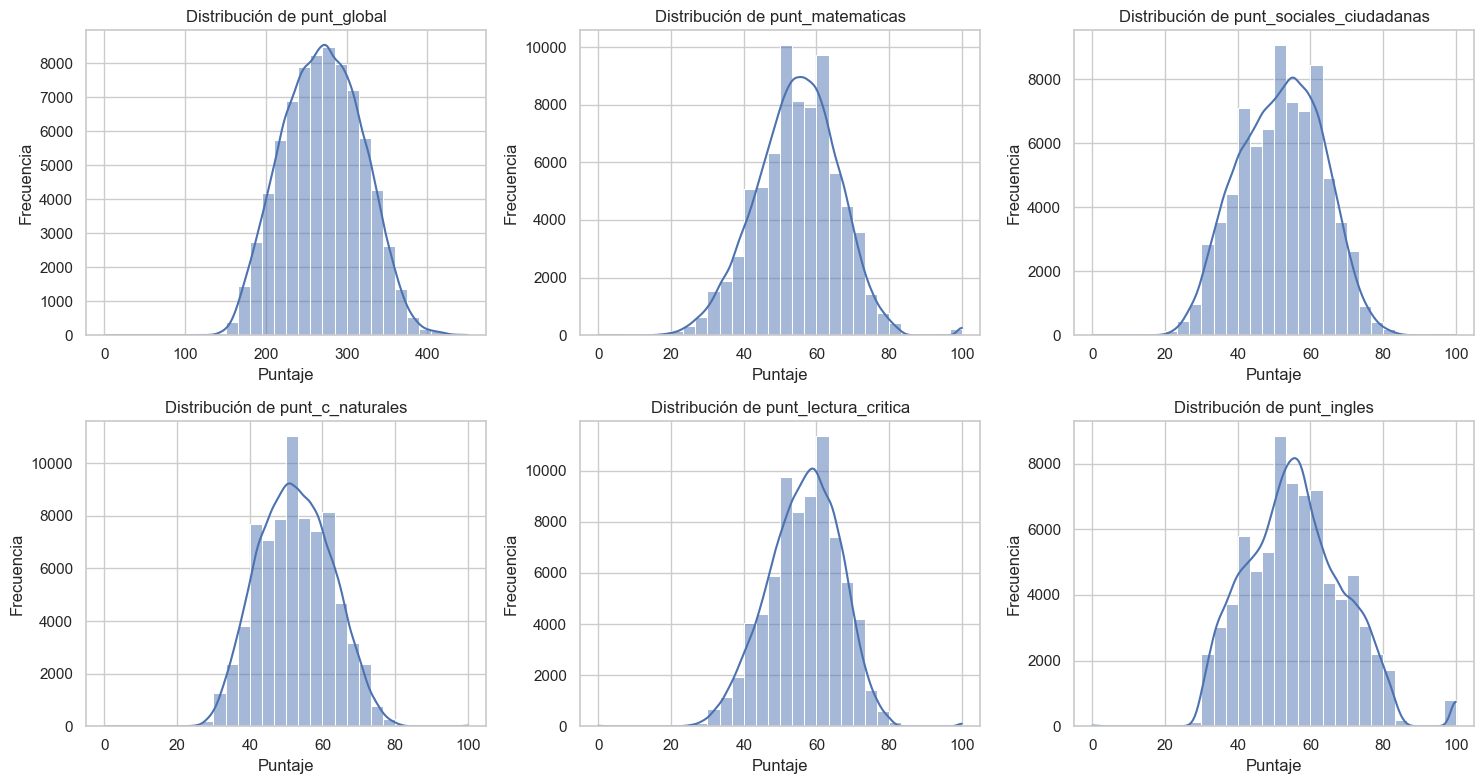

In [25]:
columnas_puntajes = ["punt_global","punt_matematicas","punt_sociales_ciudadanas","punt_c_naturales","punt_lectura_critica","punt_ingles"]

columnas_puntajes = [columna for columna in columnas_puntajes if columna in dffinal.columns]

n_variables = len(columnas_puntajes)
n_columnas = 3
n_filas = math.ceil(n_variables / n_columnas)

fig, axes = plt.subplots(n_filas,n_columnas,figsize=(15, 4 * n_filas))

axes = np.array(axes).reshape(-1)

for i, columna in enumerate(columnas_puntajes):
    sns.histplot(data=dffinal,x=columna,bins=30,kde=True,ax=axes[i]
    )

    axes[i].set_title(f"Distribución de {columna}")
    axes[i].set_xlabel("Puntaje")
    axes[i].set_ylabel("Frecuencia")

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()



## Diagramas de caja para comparar los puntajes

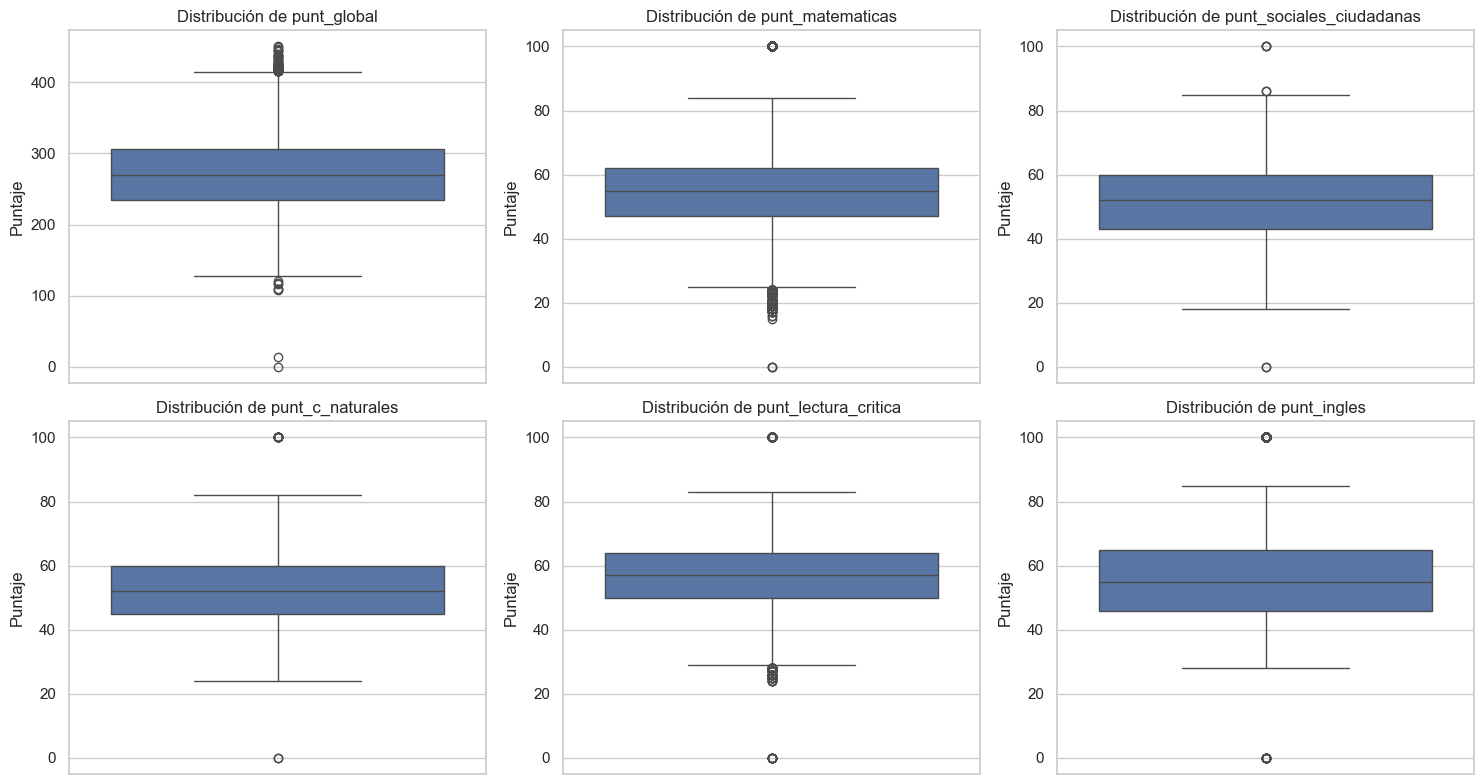

In [26]:
n_variables = len(columnas_puntajes)
n_columnas = 3
n_filas = math.ceil(n_variables / n_columnas)

fig, axes = plt.subplots(n_filas,n_columnas,figsize=(15, 4 * n_filas))

axes = np.array(axes).reshape(-1)

for i, columna in enumerate(columnas_puntajes):
    sns.boxplot(data=dffinal,y=columna,ax=axes[i])

    axes[i].set_title(f"Distribución de {columna}")
    axes[i].set_ylabel("Puntaje")

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()




**Observaciones Variables Numericas:**

- **Punt_ingles**
*Rol:* Variable numérica que corresponde al puntaje obtenido por el estudiante para la sección de ingles de la prueba saber 11. El rango de puntaje se encuentra entre 0 y 100.

*Media:* 55.735

*Desviación estándar:*  13.459, es decir 24.14% de la media

*50% central entre:* 46 – 64 puntos

En la distribución del histograma se ve una alta concentración de datos alrededor de la media, podría ser aproximadamente normal, aunque se puede evidenciar una ligera asimetría hacia la derecha.
- **Punt_matematicas**

*Rol:* Variable numérica que corresponde al puntaje obtenido por el estudiante para la sección de matematicas de la prueba saber 11. El rango de puntaje se encuentra entre 0 y 100.

*Media:* 54.824

*Desviación estándar:*  11.654, es decir 21.25% de la media

*50% central entre:* 47 – 62 puntos

En la distribución del histograma se ve una alta concentración de datos alrededor de la media, podría ser aproximadamente normal, aunque se puede evidenciar una ligera asimetría hacia la derecha.
- **Punt_sociales_ciudadanas**

*Rol:* Variable numérica que corresponde al puntaje obtenido por el estudiante para la sección de ciencias sociales y competencias ciudadanas (evalúa globalmente competencias ciudadanas, pensamiento crítico frente a problemáticas sociales y entendimiento de fenómenos sociales) de la prueba saber 11. El rango de puntaje se encuentra entre 0 y 100.

*Media:* 52.978

*Desviación estándar:*  11.420, es decir 21.55% de la media

*50% central entre:* 45 – 61 puntos

En la distribución del histograma se ve una alta concentración de datos alrededor de la media, podría ser aproximadamente normal, aunque se puede evidenciar una ligera asimetría hacia la izquierda.
- **Punt_c_naturales**

*Rol:* Variable numérica que corresponde al puntaje obtenido por el estudiante para la sección de ciencias naturales de la prueba saber 11. El rango de puntaje se encuentra entre 0 y 100.

*Media:* 53.886

*Desviación estándar:*  10.260, es decir 19.04% de la media

*50% central entre:* 47 – 61 puntos

En la distribución del histograma se ve una alta concentración de datos alrededor de la media, podría ser aproximadamente normal.
- **Punt_lectura_critica**

*Rol:* Variable numérica que corresponde al puntaje obtenido por el estudiante para la sección de lectura critica de la prueba saber 11. El rango de puntaje se encuentra entre 0 y 100.

*Media:* 55.662

*Desviación estándar:*  9.862, es decir 17.71% de la media

*50% central entre:* 49 – 63 puntos

En la distribución del histograma se ve una alta concentración de datos alrededor de la media, podría ser aproximadamente normal.
- **Punt_global**

*Rol:* Variable numérica que corresponde al puntaje total obtenido por el estudiante para la prueba saber 11, siendo obtenida de la suma de los puntajes de las 5 secciones que componen el examen. El rango de puntaje se encuentra entre 0 y 500.

*Media:* 272.228

*Desviación estándar:*  49.128, es decir 18.04% de la media

*50% central entre:* 237 – 306 puntos
En la distribución del histograma se ve una alta concentración de datos alrededor de la media, podría ser aproximadamente normal.

- **Correlaciones**
Se evidencia una alta correlación entre todas las variables numéricas, lo cual guarda sentido en el marco del evento que estamos describiendo (si un estudiante obtiene un buen puntaje en una materia, es muy probable que obtenga buenas notas en otras materias).
Evidenciamos una correlación especialmente alta entre punt_global vs las demás variables numéricas, ya que el puntaje global se calcula a partir de la suma de los demás puntajes.

## Frecuencias de variables categóricas

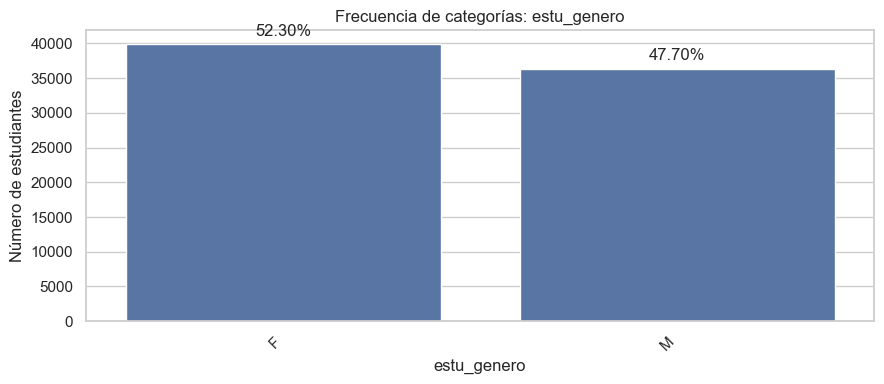

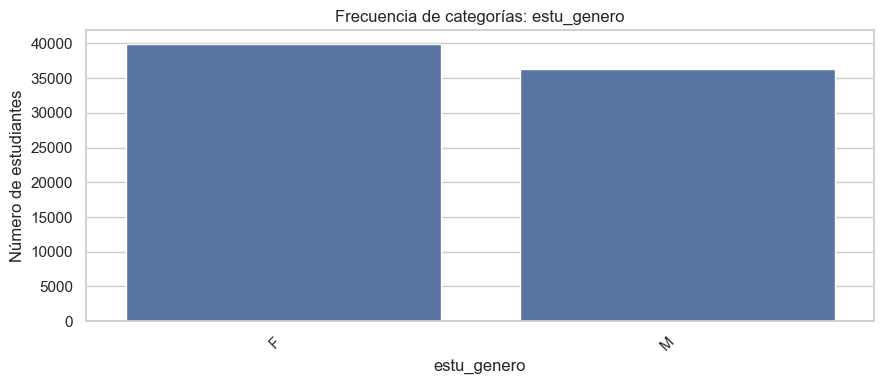

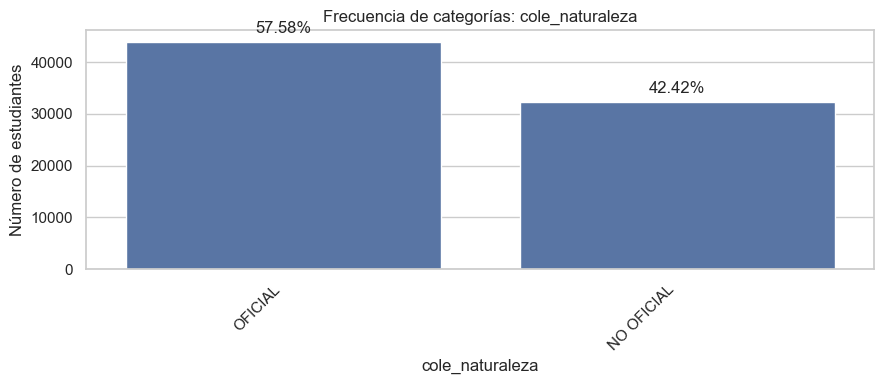

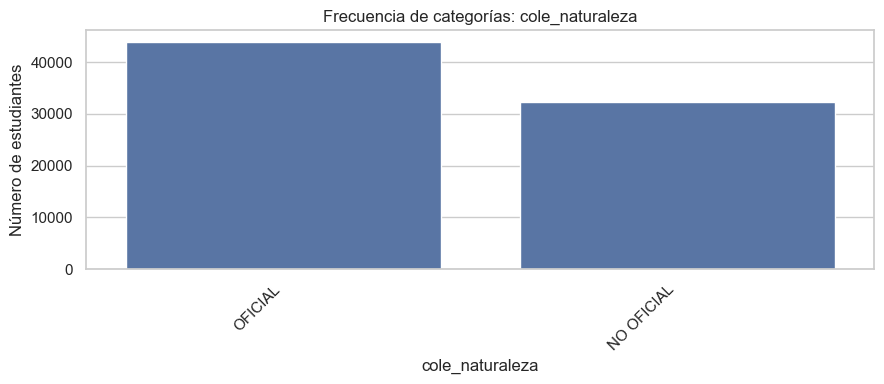

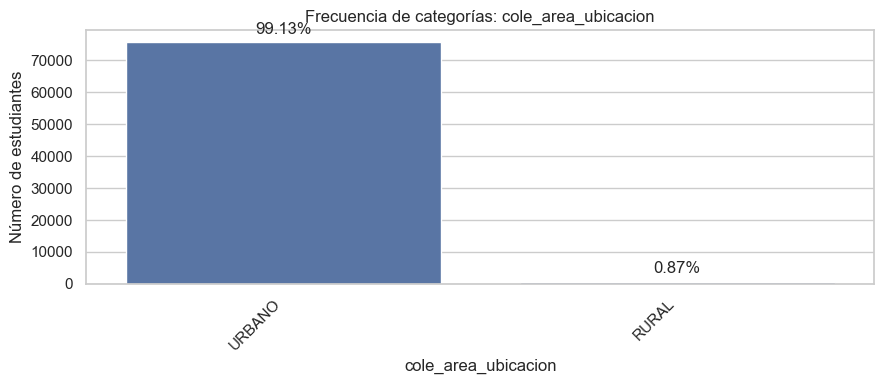

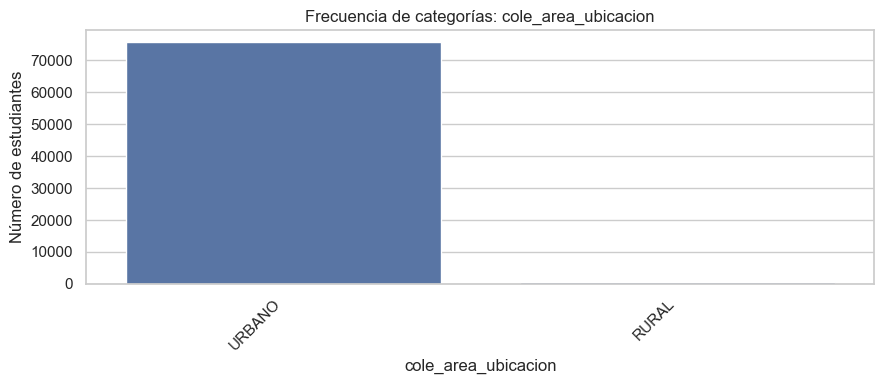

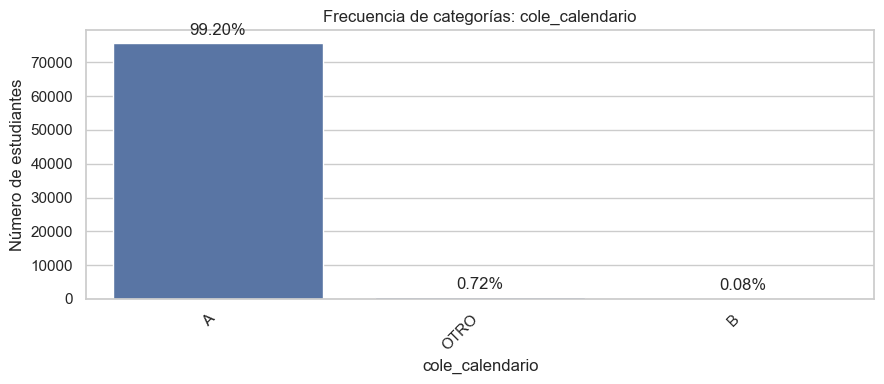

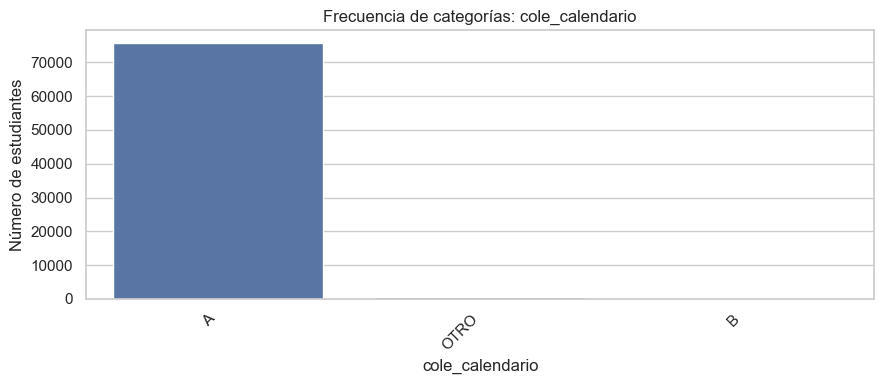

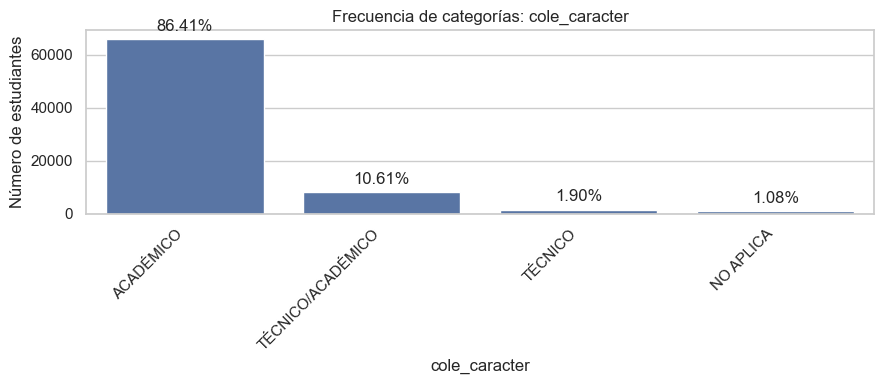

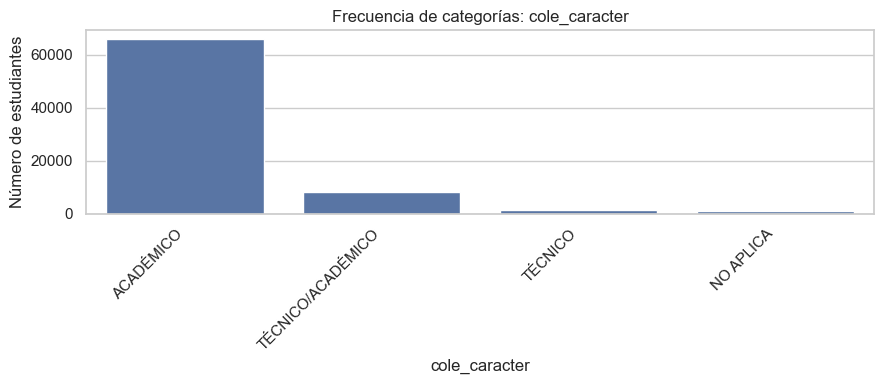

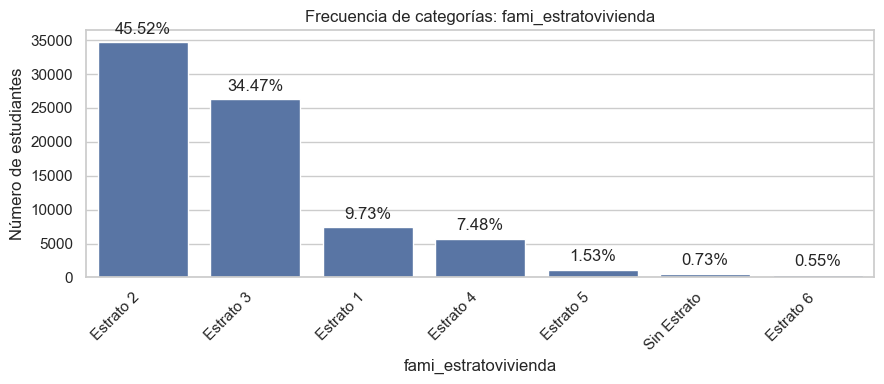

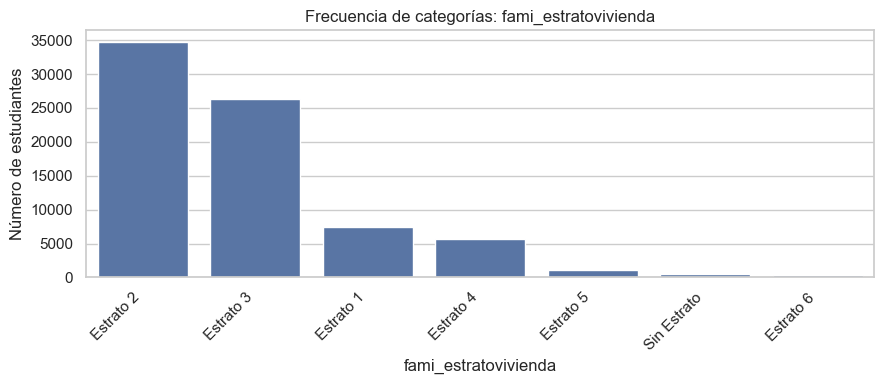

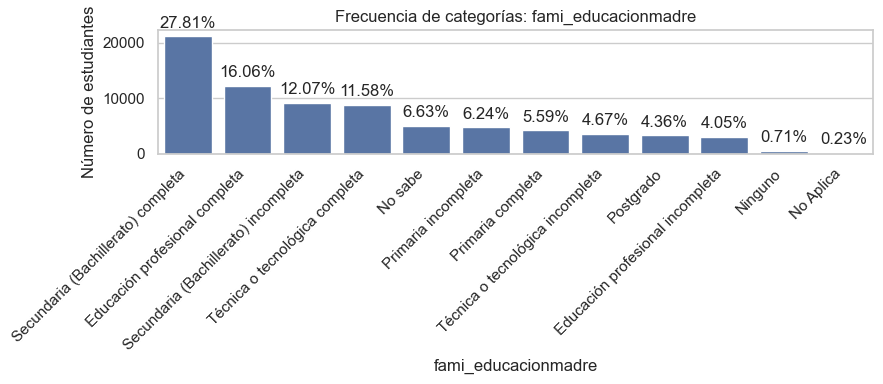

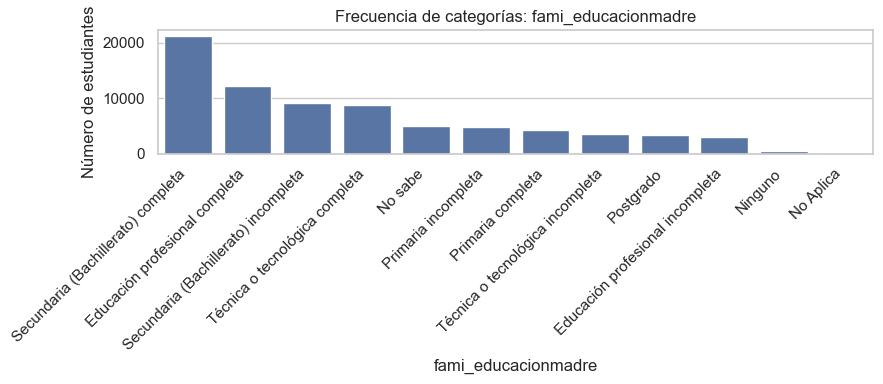

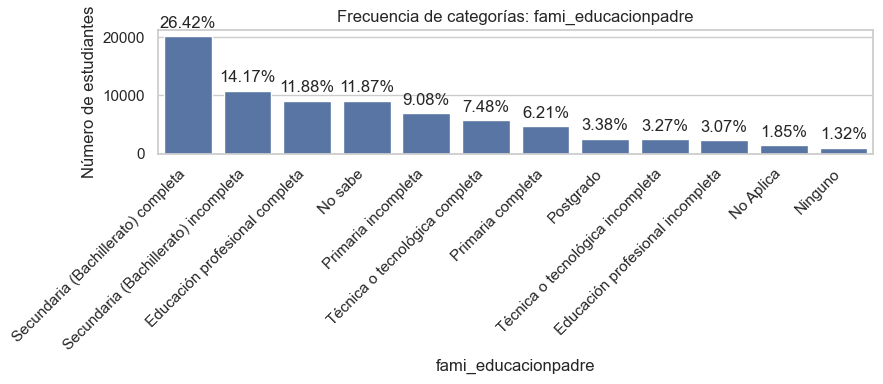

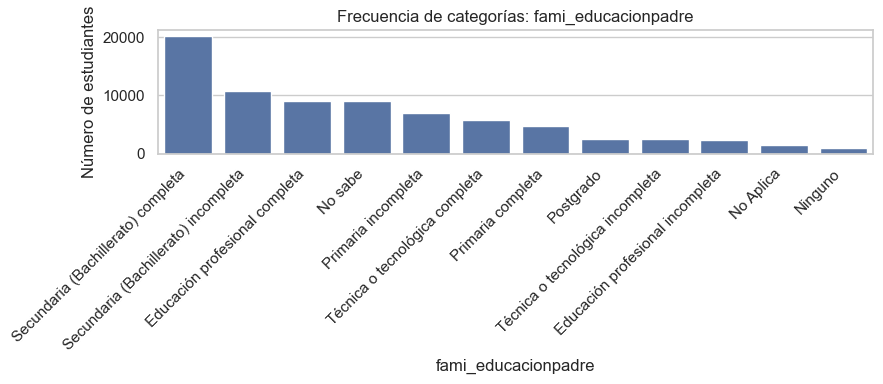

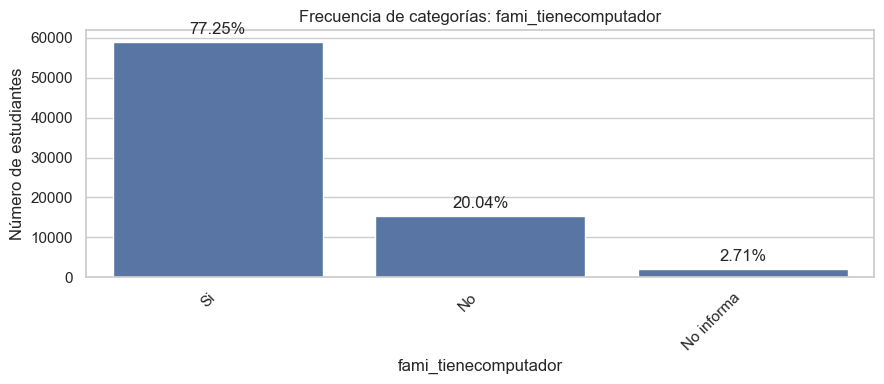

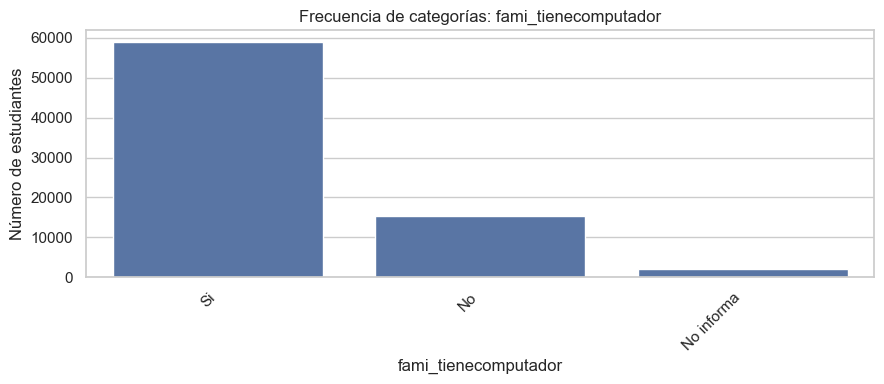

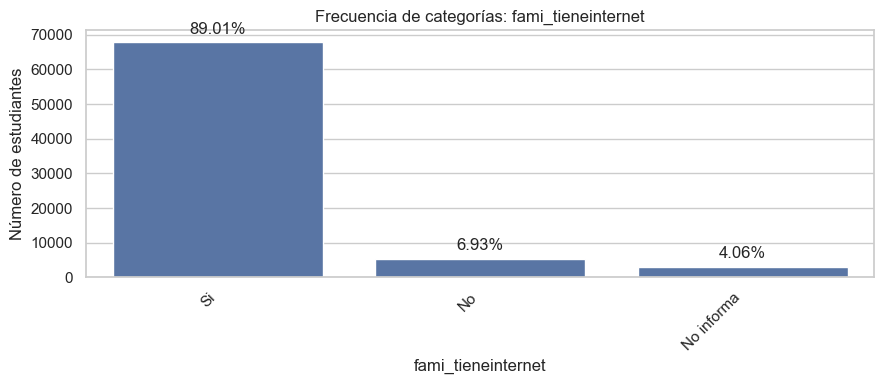

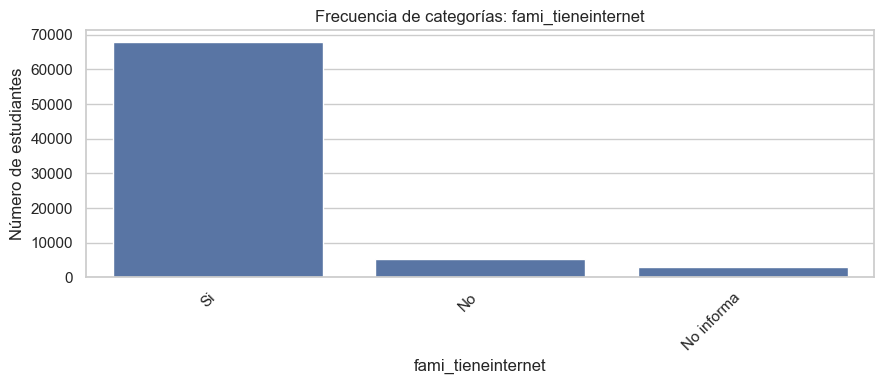

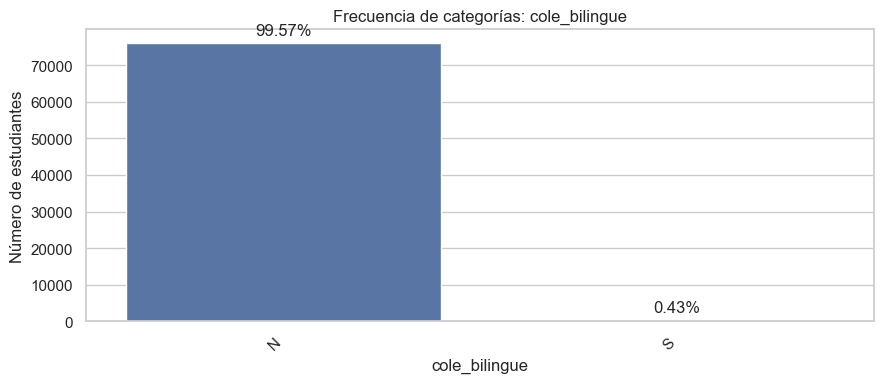

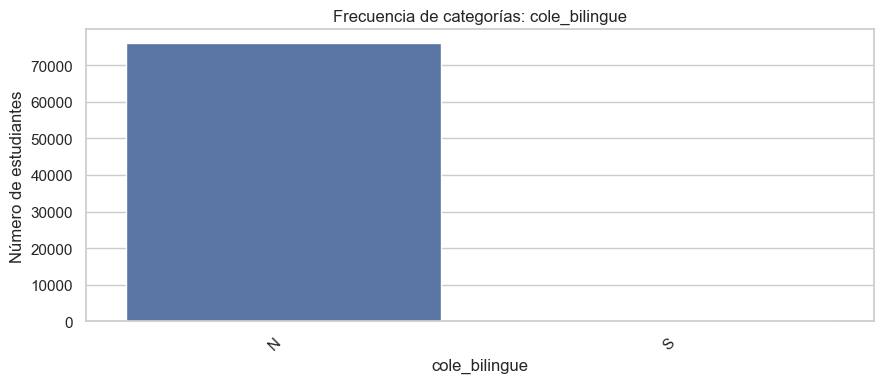

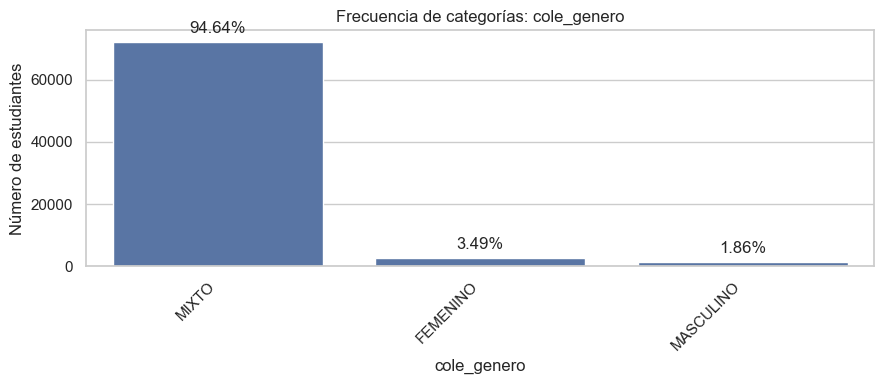

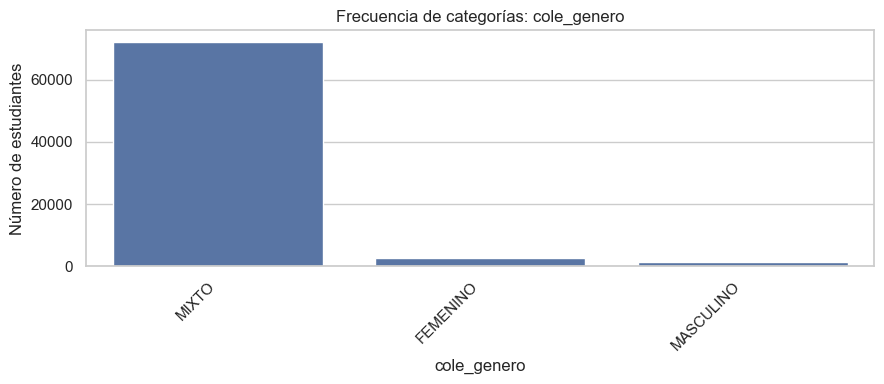

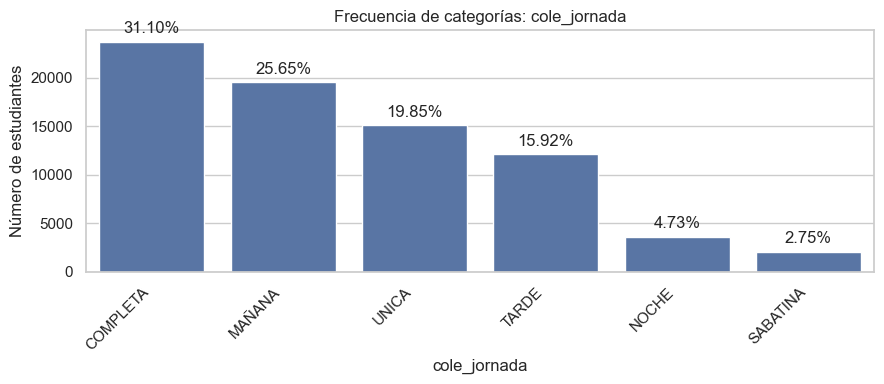

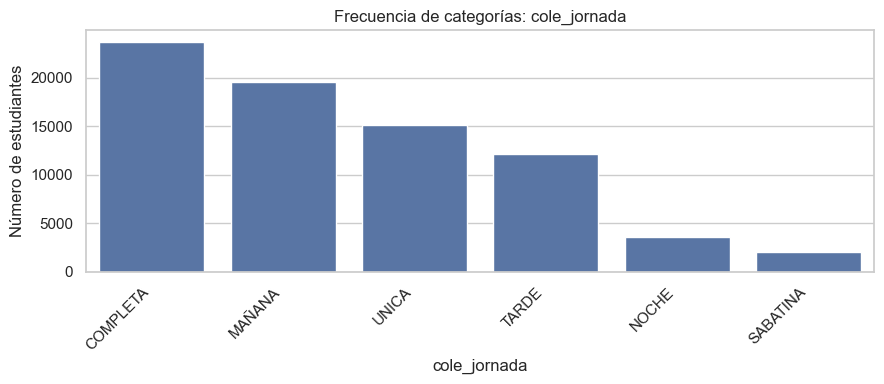

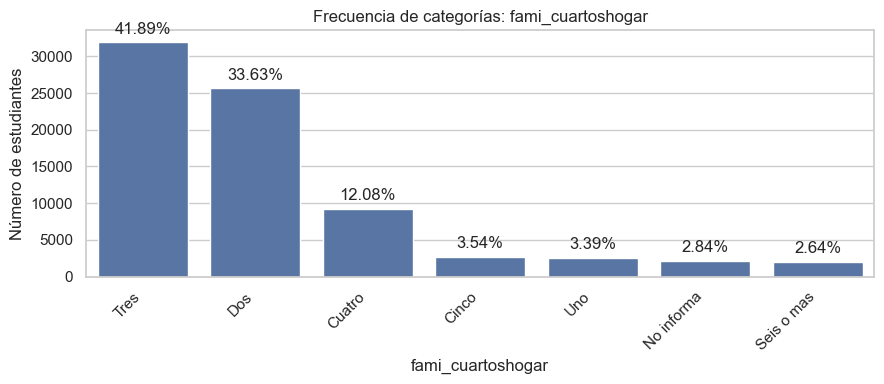

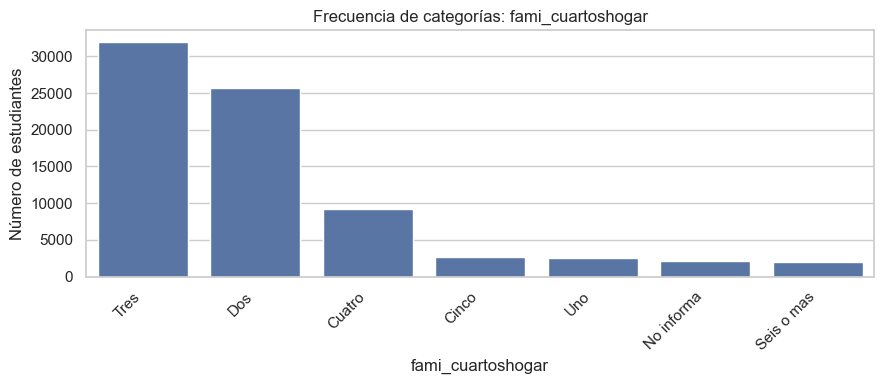

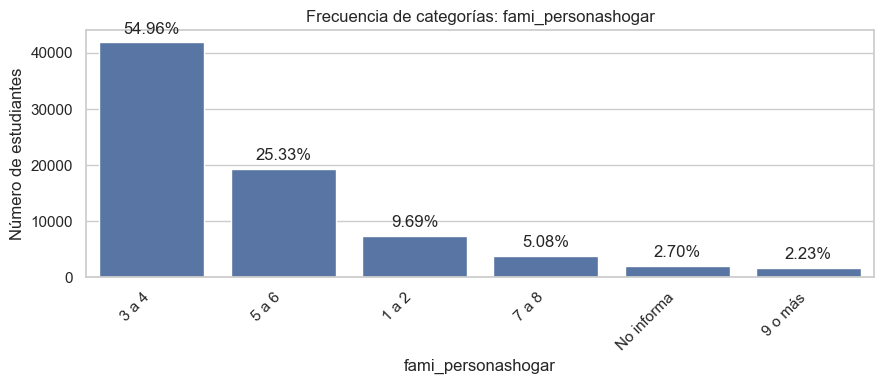

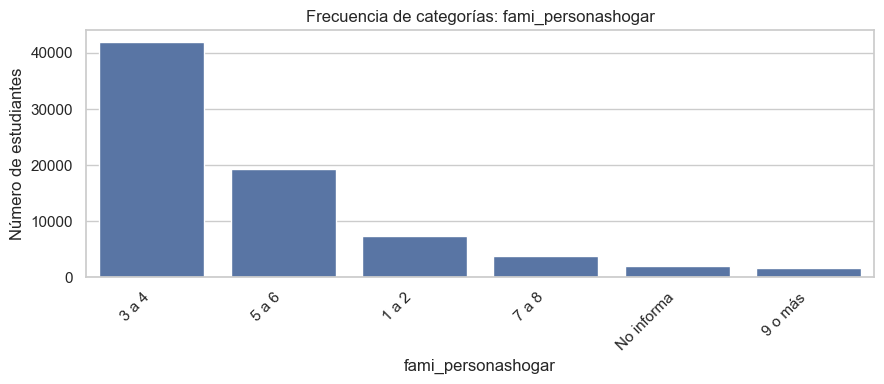

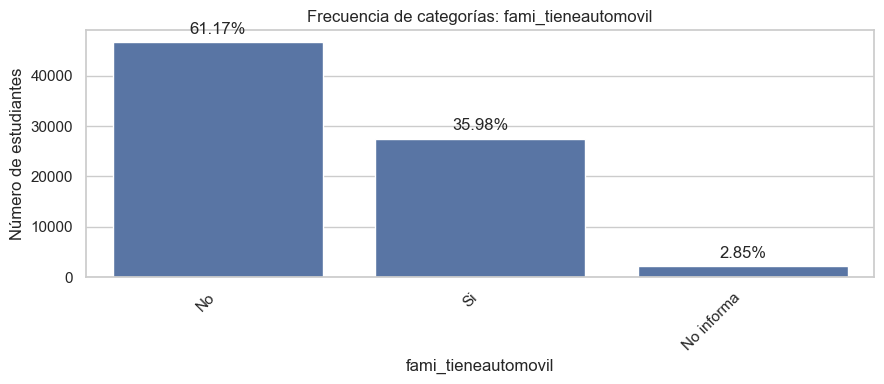

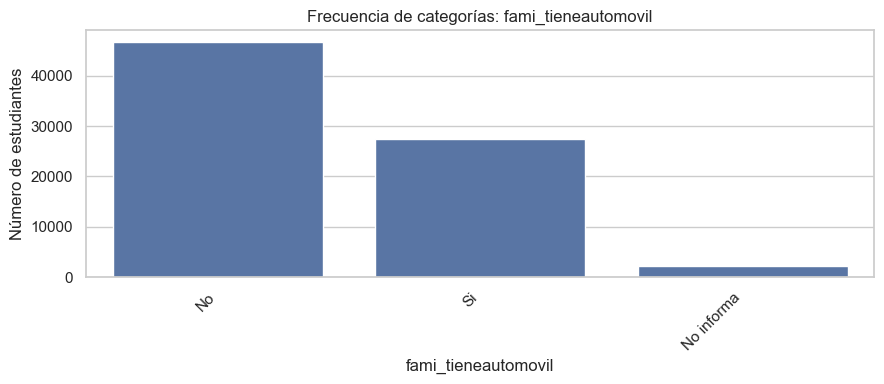

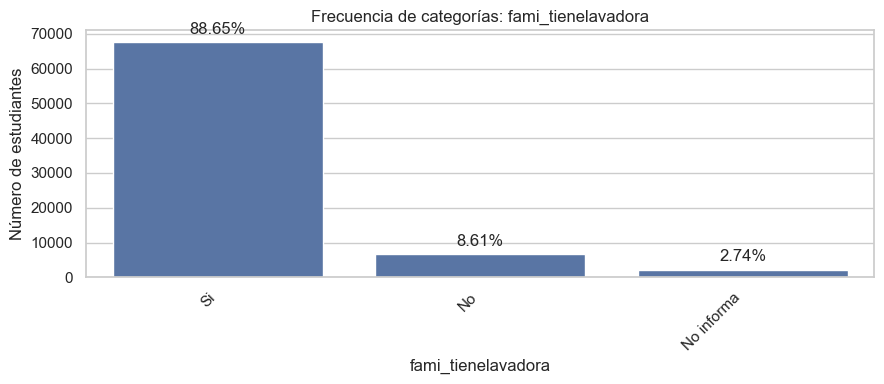

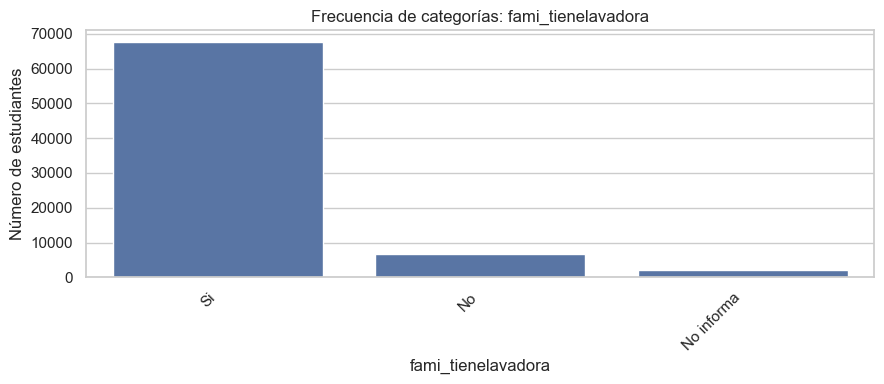

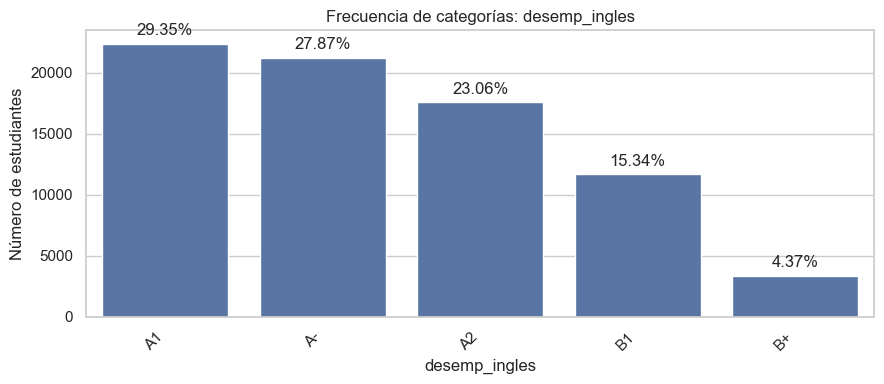

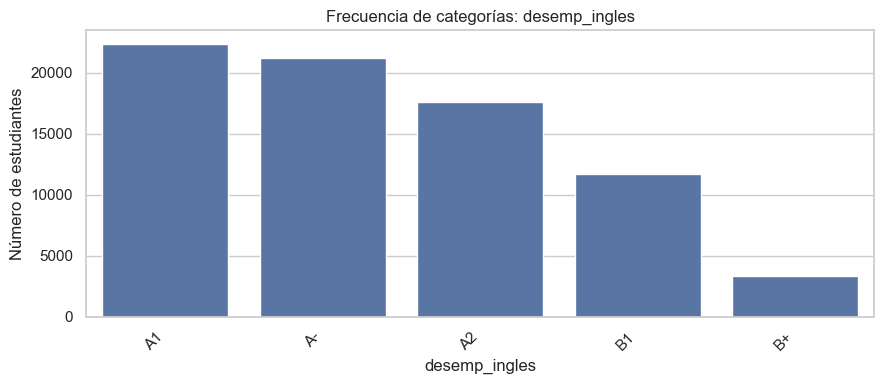

In [27]:
# Seleccionar variables útiles para el problema de negocio.
variables_categoricas_interes = [
    "estu_genero",
    "cole_naturaleza",
    "cole_area_ubicacion",
    "cole_calendario",
    "cole_caracter",
    "fami_estratovivienda",
    "fami_educacionmadre",
    "fami_educacionpadre",
    "fami_tienecomputador",
    "fami_tieneinternet",
    "cole_bilingue",
    "cole_genero",
    "cole_jornada",
    "fami_cuartoshogar",
    "fami_personashogar",
    "fami_tieneautomovil",
    "fami_tienelavadora",
    "desemp_ingles"
]

variables_categoricas_interes = [columna for columna in variables_categoricas_interes if columna in dffinal.columns]

for columna in variables_categoricas_interes:

    frecuencias = dffinal[columna].value_counts(dropna=False).head(15)

    plt.figure(figsize=(9, 4))

    ax = sns.barplot(x=frecuencias.index.astype(str),y=frecuencias.values)

    # Agregar porcentajes encima de cada barra
    total = dffinal[columna].notna().sum()

    for barra, cantidad in zip(ax.patches, frecuencias.values):
        porcentaje = cantidad / total * 100 if total > 0 else 0

        ax.annotate(f"{porcentaje:.2f}%",
            (barra.get_x() + barra.get_width() / 2, barra.get_height()),
            ha="center",
            va="bottom",
            xytext=(0, 4),
            textcoords="offset points"
        )

    plt.title(f"Frecuencia de categorías: {columna}")
    plt.xlabel(columna)
    plt.ylabel("Número de estudiantes")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(9, 4))

    sns.barplot(x=frecuencias.index.astype(str),y=frecuencias.values)

    plt.title(f"Frecuencia de categorías: {columna}")
    plt.xlabel(columna)
    plt.ylabel("Número de estudiantes")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()




## Tabla de frecuencias porcentuales

In [28]:
for columna in variables_categoricas_interes:
    frecuencias = (dffinal[columna].value_counts(dropna=False, normalize=True).mul(100).round(2).head(15))

    print(f"\nDistribución porcentual de {columna}")
    display(frecuencias.rename("porcentaje").rename_axis("categoría").reset_index())


Distribución porcentual de estu_genero


,categoría,porcentaje
0,F,52.3
1,M,47.7



Distribución porcentual de cole_naturaleza


,categoría,porcentaje
0,OFICIAL,57.58
1,NO OFICIAL,42.42



Distribución porcentual de cole_area_ubicacion


...

,categoría,porcentaje
0,No,61.17
1,Si,35.98
2,No informa,2.85



Distribución porcentual de fami_tienelavadora


,categoría,porcentaje
0,Si,88.65
1,No,8.61
2,No informa,2.74



Distribución porcentual de desemp_ingles


,categoría,porcentaje
0,A1,29.35
1,A-,27.87
2,A2,23.06
3,B1,15.34
4,B+,4.37


**Observaciones Variables Categoricas**


**Periodo**
- Variable categórica corresponde al año-semestre en el cuál se presentó la prueba ICFES, en términos de información, no aporta información relevante para predecir la variable objetivo.
- Inicialmente tenemos información desde el 2014 hasta el 2022.
- La categoría más frecuente es 20194 (23.28%)
- Encontramos que para todos los años y semestres la cantidad de estudiantes varía y hay algunos años como el 2014, 2018 y 2020 que no cuentan con los dos semestre del año.

**Cole_area_ubicacion**
- Indica si el colegio se encuentra en zona rural o urbano, puede contribuir a predecir la categoría de aprueba o no, suponiendo que hay diferencias marcadas en los niveles de educación en ambas zonas, Sin embargo ya que la mayoría de datos se concentran en urbano, puede que no aporte mucho para la predicción.
- La categoría más frecuente es Urbano (99.09%)
- El dataset no está equilibrado respecto a la distribución en estas dos categorías.

**Cole_calendario**
- Indica si el colegio del estudiante que presentó la prueba icfes corresponde a Calendario A, Calendario B y otro modelo flexible. Ya que los colegios públicos se encuentran en su mayoría en calendario A y los bilingües o internacionales manejan calendario B, esta variable podría ayudarnos a identificar que tipos de colegio y temporalidad definen si un estudiante aprueba o no el ICFES.
- La categoría más frecuente es A (95.74%)
- El dataset no está equilibrado en este aspecto, pero vemos que es una característica inherente a la distribución de colegios en Bogotá.
  
**Cole_caracter**
- Indica el tipo de colegio en el cual se encontraba el estudiante que presentó la prueba, tenemos las categorías: Académico, Técnico, Técnico/Académico y No Aplica. Esta variable puede ayudarnos a predecir si un estudiante aprueba o no cuando el colegio tiene un énfasis adicional hacía la parte técnica del mundo laboral.
- La categoría más frecuente es Académico (87.10%).

**Cole_genero**
- Indica si el colegio es Femenino, Masculino o Mixto, nos puede ayudar a predecir si un estudiante aprueba o no por pertenecer a alguna de estas categorías.
- La categoría más frecuente es Mixto (93.12%)
- Se observa una concentración muy alta en esta variable.

**Cole_jornada**
- Variable categórica que corresponde a: Completa, mañana, noche, sabatina, tarde y única. Puede aportar información relevante si la calidad de la educación varía respecto a esta distribución.
- La categoría más frecuente es Completa (36.48%)
- El dataset está relativamente equilibrado respecto a la distribución sus categorías.

**cole_naturaleza**
- Indica si la educación (Oficial) o negativo (No oficial), con base en la variable Resultado.
- La categoría más frecuente es Oficial y no aprueba (83.1%)
- El dataset está relativamente equilibrado en No oficial respecto a la distribución en estas dos categorías.

**estu_genero**
- Indica el sexo del estudiante Femenino (F) o Masculino (M) o N.D, con base en la variable Resultado.
- La categoría más frecuente es F no aprueba (74.2%)
- El dataset hay mas data en el sexo F respecto a la distribución en estas tres categorías.

**estu_privado_libertad**
- Indica si el estudiante estudia privado o publico es (S) o negativo (N), con base en la variable Resultado.
- La categoría más frecuente es N no aprueba (71.1%)
- El dataset está muy inclinado a la parte de N respecto a la distribución en estas dos categorías.

**fami_cuartoshogar**
- Indica la cantidad de cuartos en el hogar desde 1 hasta 6 o mas, con base en la variable Resultado.
- La categoría más frecuente es tres no aprueba (67.5%)
- El dataset hay mas información en la categoría tres en la distribución en estas seis categorías.

**fami_educacionmadre**
- Indica si la educación de la madre si es primaria, secundaria, técnica, profesional, postgrado, no sabe, ninguno, no aplica con base en la variable
- La categoría más frecuente es bachillerato incompleta y no aprueba (78.5%)
- El dataset está enfocado en la sección de bachillerato incompleta a la distribución en estas 11 categorías.

**fami_educacionpadre**
- Indica si la educación del padre si es primaria, secundaria, técnica, profesional, postgrado, no sabe, ninguno, no aplica, con base en la variable.
- La categoría más frecuente es Secundario (Bachillerato) incompleta y no aprueba (77.0%)
- El dataset está enfocado en la sección de bachillerato incompleta a la distribución en estas 11 categorías.

**fami_estratovivienda**
- Se evidencia mayor concentracion de estudiantes de estratos *2 y 3*, sumando el 77% del total de registros.
- A mayor Estrato, se logran aprobar en mayor proporcion las pruebas ICFES.
- No se evidencia correlacion individual con la variable objetivo (Resultado).

**fami_personashogar**
- Se evidencia mayor concentracion de estudiantes con *3 a 6* personas en su nucleo familiar, sumando un 82% del total de registros.
- A mayor numero de personas en el hogar, el % de aprobacion disminuye considerablemente.
- No se evidencia correlacion individual con la variable objetivo (Resultado).

**fami_tieneautomovil**
- Se evidencia mayor concentracion de estudiantes *sin automovil* (63%).
- El % de aprobacion aumenta 2X cuando el estudiante *si tiene automovil*.
- No se evidencia correlacion individual con la variable objetivo (Resultado).

**fami_tienecomputador**
- Se evidencia una alta concentracion en estudiantes que *si poseen computador* en el hogar (81%).
- El % de aprobacion aumenta 3X al tener computador en el hogar.
- No se evidencia correlacion individual con la variable objetivo (Resultado).
  
**fami_tieneinternet**
- Se evidencia alta concentracion de estudiantes que *si tienen acceso a internet* en el hogar (87%).
- El % de aprobacion aumenta 3X cuando el estudiante *si tiene acceso a internet*.
- No se evidencia correlacion individual con la variable objetivo (Resultado). Existen comportamientos similares con la variable *fami_tienecomputador*, sin embargo no hay una correlacion alta entre ellos.

**fami_tienelavadora**
- Se evidencia una alta concentracion en estudiantes que *si cuentan con lavadora* en el hogar (88%).
- El % de aprobacion de la prueba aumenta 2X cuando el estudiante *si tiene lavadora* en el hogar.
- No se evidencia correlacion individual con la variable objetivo (Resultado).

**Resultados**

*Rol:* Es nuestra *variable de respuesta*, que está compuesta por dos clases: ***Aprueba*** y ***No Aprueba***. Estas clases fueron estructuradas definiendo un threshold para el puntaje global siendo mayor o igual a 300 puntos para aprobar.

En nuestro dataset el 71.06% de las observaciones hacen referencia a estudiantes que no aprobaron y el 28.93% corresponde a observaciones de estudiantes que aprobaron.

Las clases están parcialmente equilibradas, estando concentradas en la clase “No Aprueba”. Esto se presenta dado que nuestro threshold está por encima de la media del puntaje global. Esta variable guarda una correlación perfecta con punt_global.

#### *Estas variables categoricas, que agrupan las condiciones socioeconomicas del hogar de cada estudiante, tienen una relevancia significativa en la explicacion del desempeño en las pruebas. No presentan una colinealidad entre si ni con la variable objetivo, esto permite que su aporte al modelo seleccionado sea complementaria y no genere redundancia.*

# Relaciones entre variables y hallazgos exploratorios 

## Correlación entre puntajes numéricos

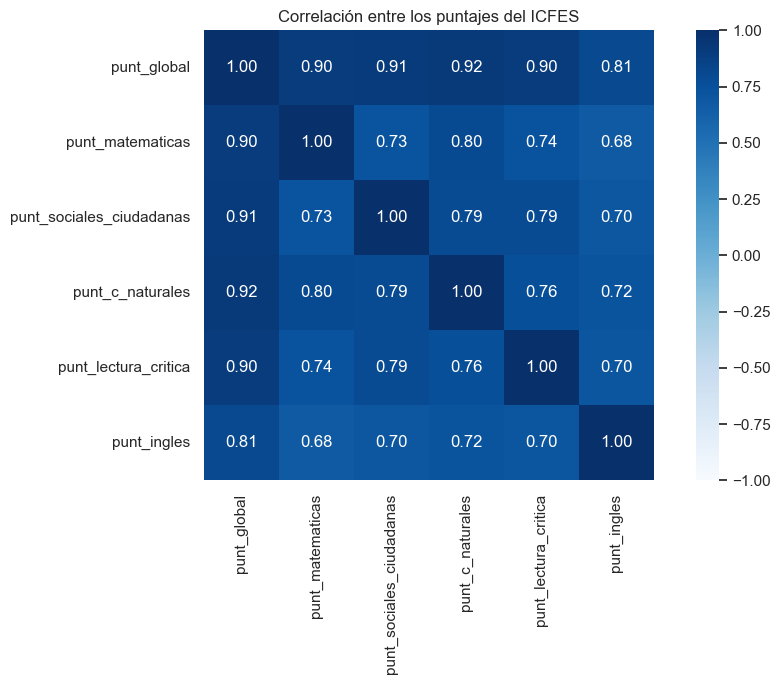

,punt_global,punt_matematicas,punt_sociales_ciudadanas,punt_c_naturales,punt_lectura_critica,punt_ingles
punt_global,1.000000,0.898961,0.912915,0.918587,0.899115,0.810362
punt_matematicas,0.898961,1.000000,0.732511,0.801569,0.739226,0.677231
punt_sociales_ciudadanas,0.912915,0.732511,1.000000,0.793408,0.791996,0.699901
punt_c_naturales,0.918587,0.801569,0.793408,1.000000,0.758824,0.720002
punt_lectura_critica,0.899115,0.739226,0.791996,0.758824,1.000000,0.703837
punt_ingles,0.810362,0.677231,0.699901,0.720002,0.703837,1.000000


In [29]:
columnas_puntajes = [
    "punt_global",
    "punt_matematicas",
    "punt_sociales_ciudadanas",
    "punt_c_naturales",
    "punt_lectura_critica",
    "punt_ingles"
]

columnas_puntajes = [columna for columna in columnas_puntajes if columna in dffinal.columns]

matriz_correlacion = dffinal[columnas_puntajes].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlación entre los puntajes del ICFES")
plt.tight_layout()
plt.show()

display(matriz_correlacion)

## Análisis de puntaje por variable categórica

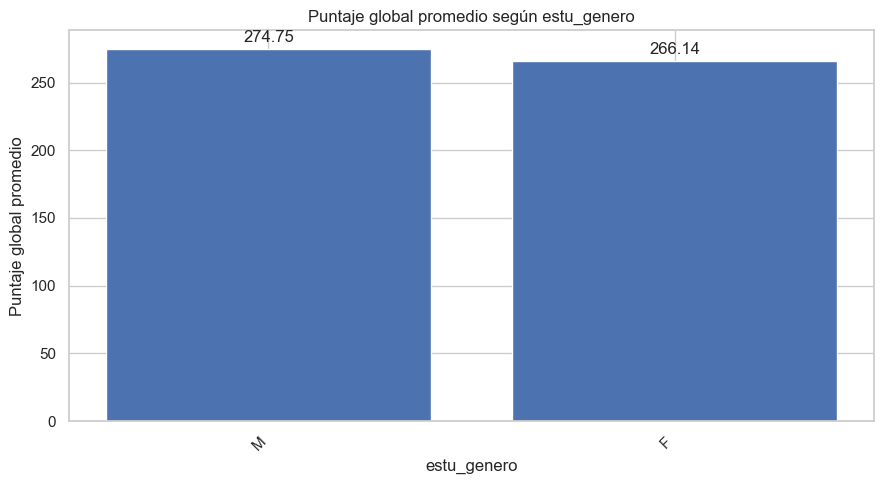

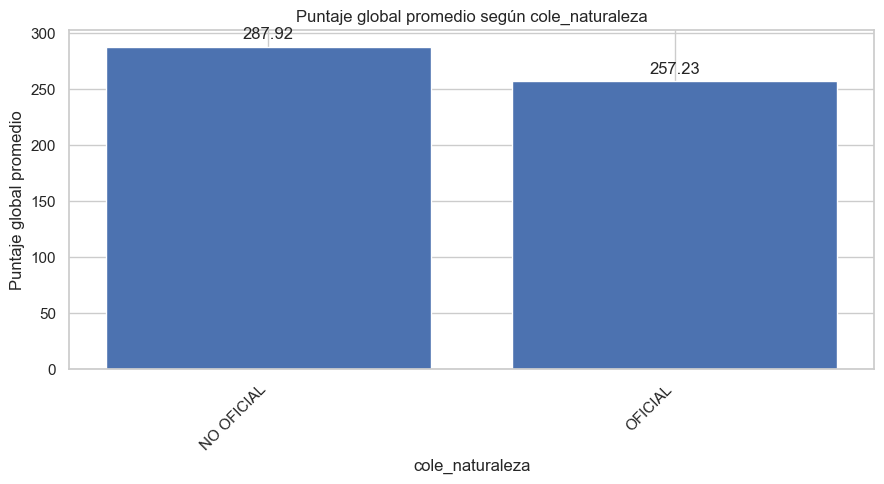

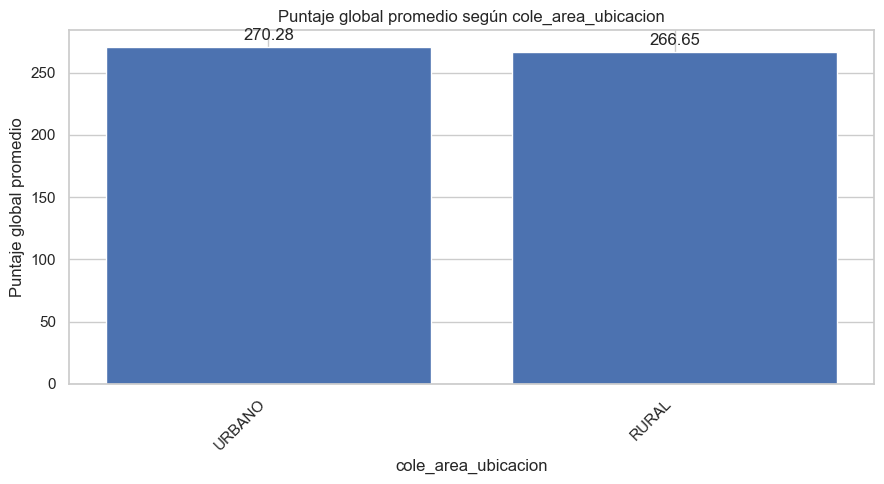

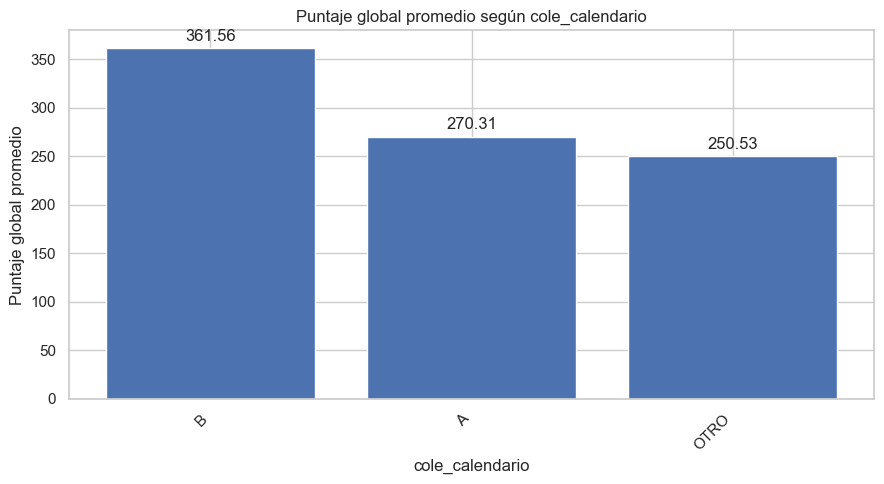

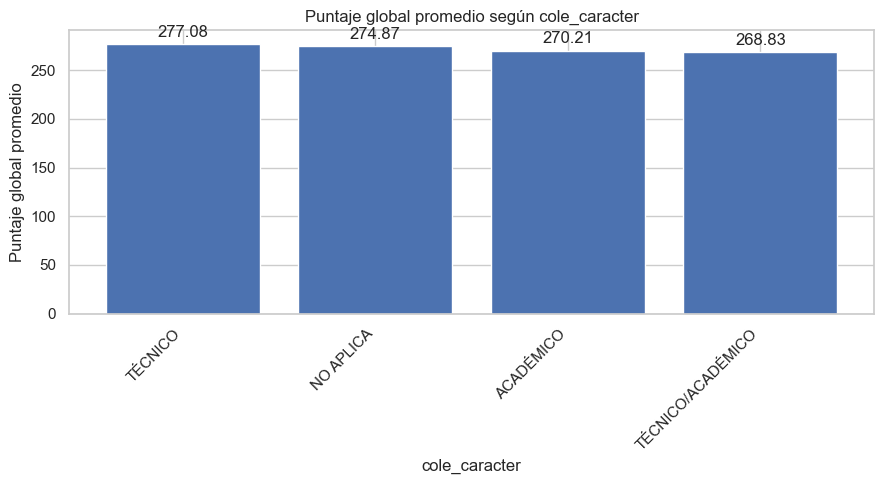

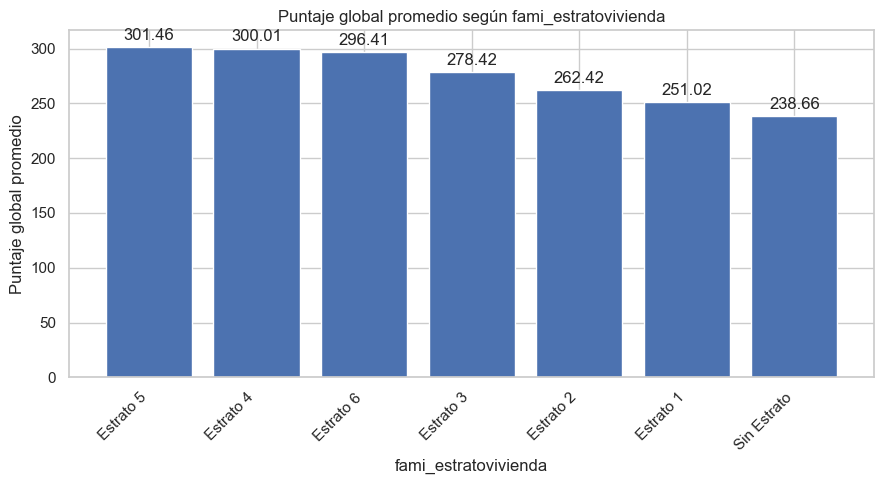

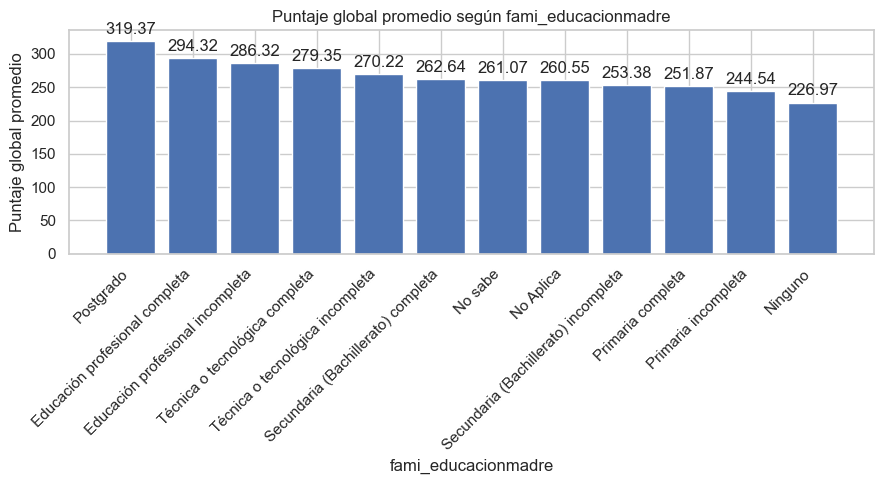

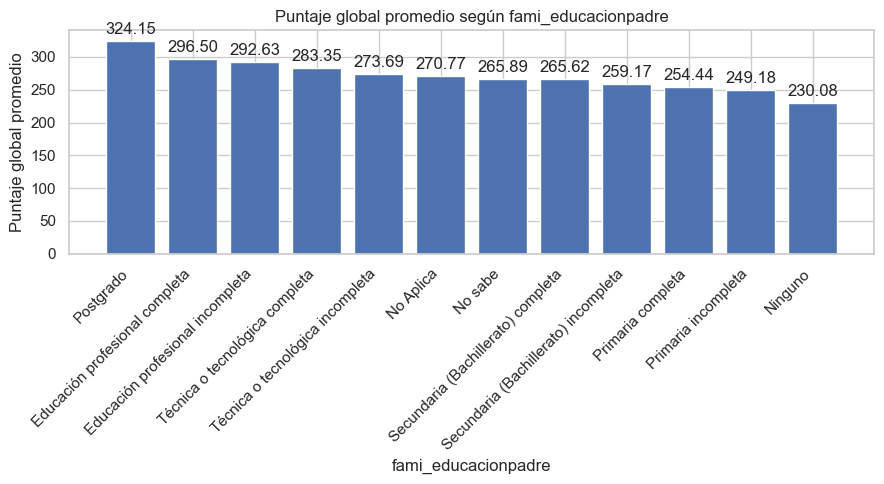

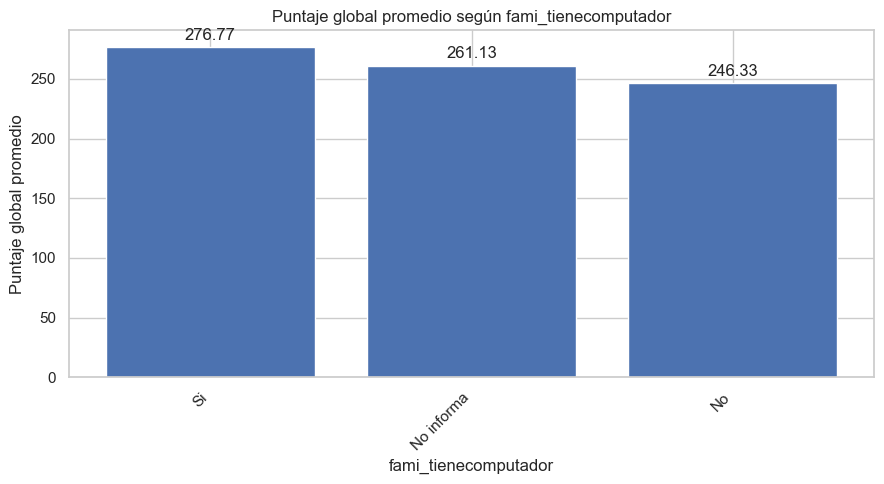

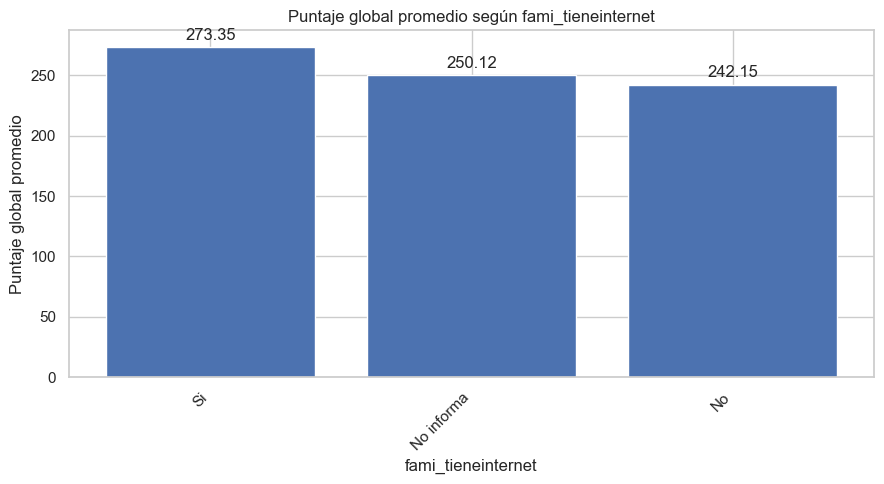

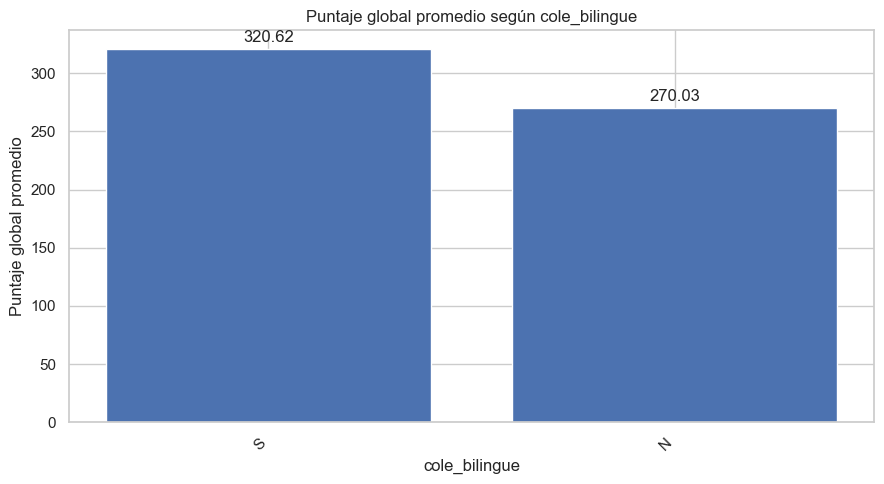

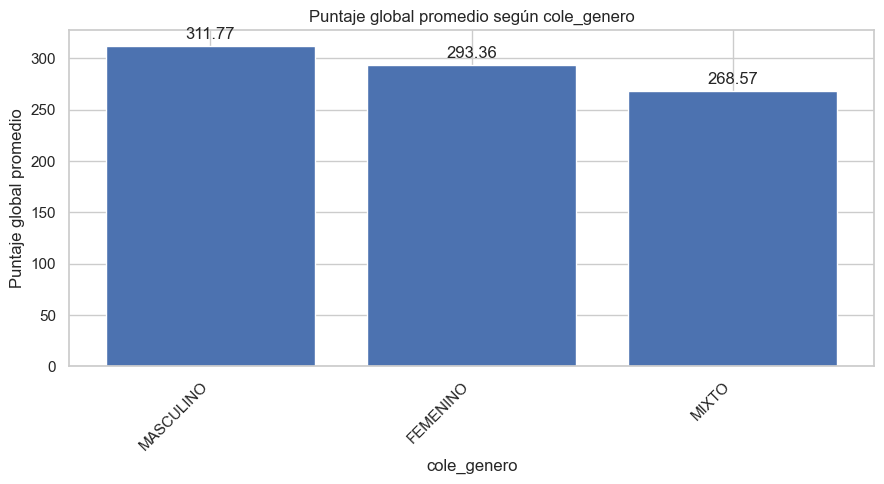

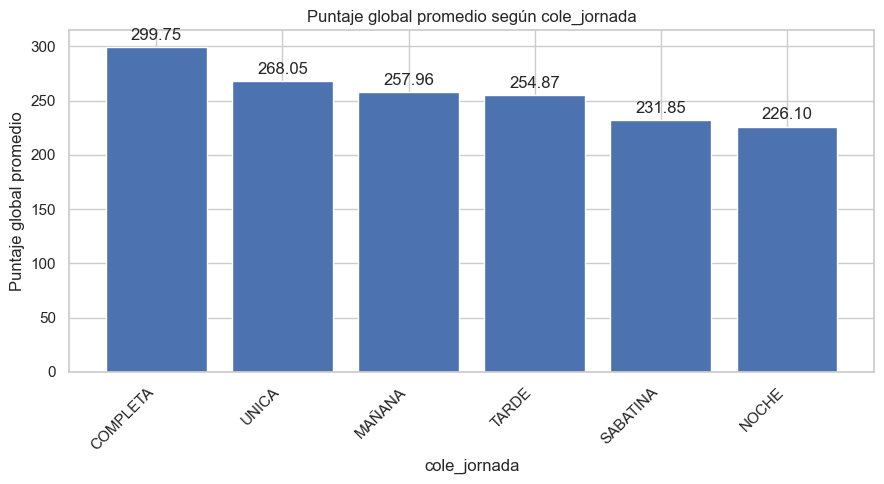

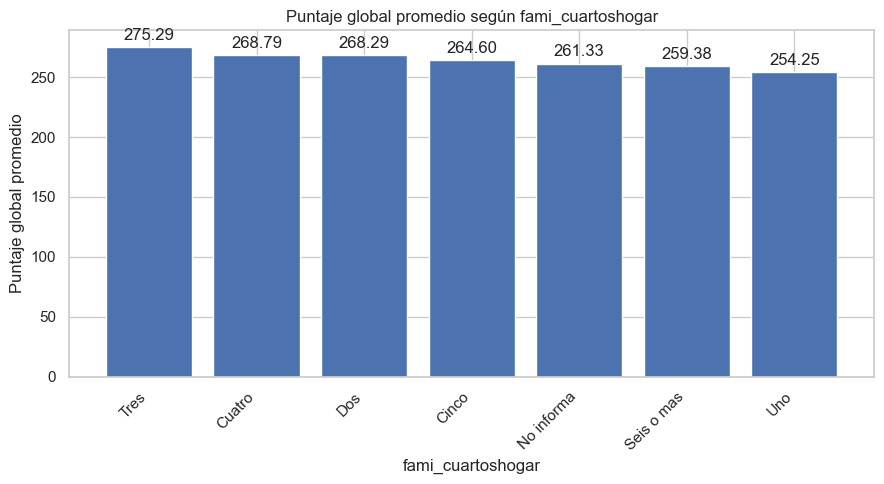

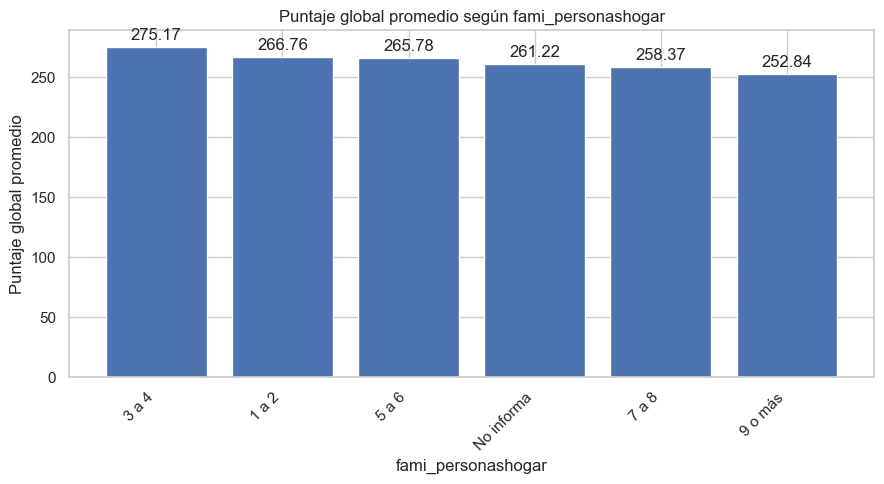

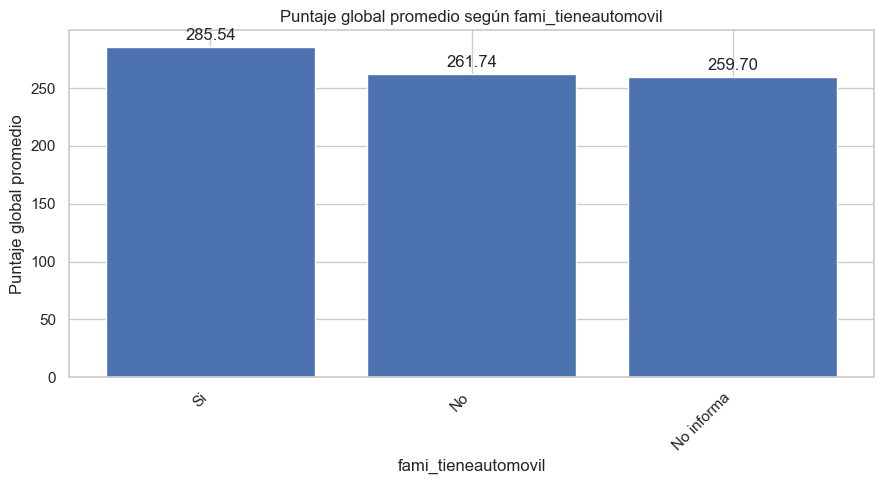

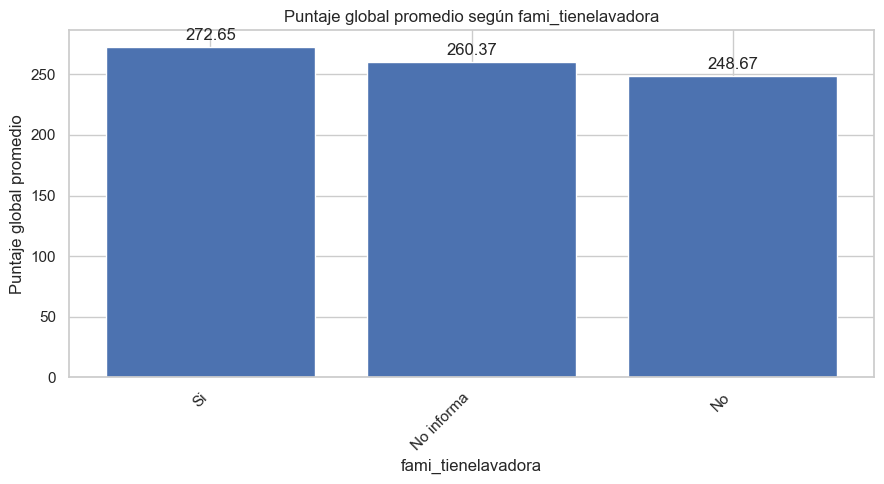

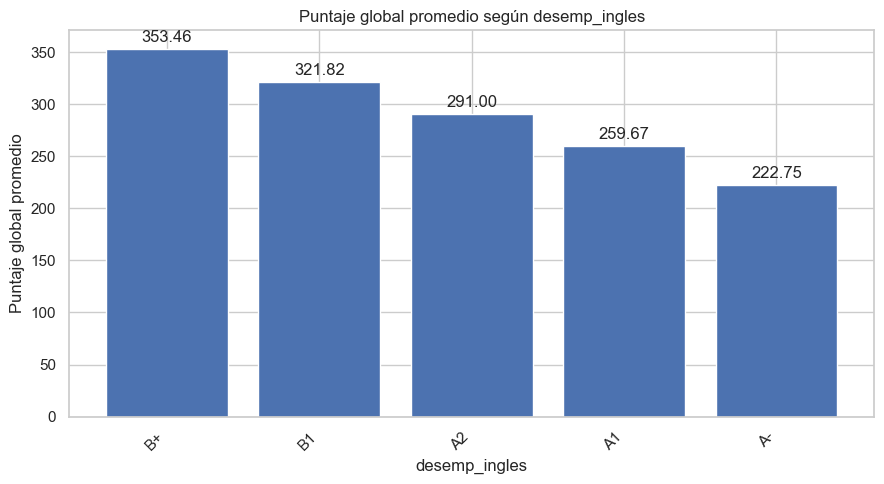

In [30]:
# Crear una gráfica para cada variable categórica
for variable in variables_categoricas_interes:

    # Calcular el puntaje global promedio por categoría
    promedios = (
        dffinal.groupby(variable, observed=True)["punt_global"]
        .mean()
        .sort_values(ascending=False)
    )

    # Crear la gráfica
    plt.figure(figsize=(9, 5))
    barras = plt.bar(
        promedios.index.astype(str),
        promedios.values
    )

    # Mostrar los valores sobre las barras
    plt.bar_label(barras, fmt="%.2f", padding=3)

    # Personalizar
    plt.title(f"Puntaje global promedio según {variable}")
    plt.xlabel(variable)
    plt.ylabel("Puntaje global promedio")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()










Se define la variable resultado con base en el criterio de aprobación puntaje global >= 300

DISTRIBUCIÓN DE LA VARIABLE RESULTADO


,cantidad,porcentaje
resultado,,
No aprueba,54079,70.92
Aprueba,22174,29.08


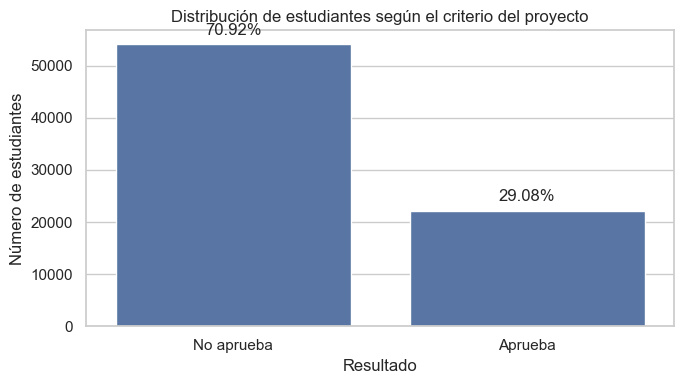

In [31]:
dffinal["Resultado"] = np.where(dffinal["punt_global"] >= 300,"Aprueba","No aprueba")

dffinal["Resultado"] = dffinal["Resultado"].astype("category")

print("DISTRIBUCIÓN DE LA VARIABLE RESULTADO")

tabla_resultado = (dffinal["Resultado"].value_counts(dropna=False).rename_axis("resultado").to_frame("cantidad"))

tabla_resultado["porcentaje"] = (tabla_resultado["cantidad"] / len(dffinal) * 100).round(2)

display(tabla_resultado)


plt.figure(figsize=(7, 4))

ax = sns.countplot(
    data=dffinal,
    x="Resultado",
    order=["No aprueba", "Aprueba"]
)

# Agregar el porcentaje encima de cada barra
total = len(dffinal)

for barra in ax.patches:
    altura = barra.get_height()
    porcentaje = altura / total * 100

    ax.annotate(
        f"{porcentaje:.2f}%",
        (barra.get_x() + barra.get_width() / 2, altura),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.title("Distribución de estudiantes según el criterio del proyecto")
plt.xlabel("Resultado")
plt.ylabel("Número de estudiantes")
plt.tight_layout()
plt.show()



## Comparar resultados por variables Categóricas

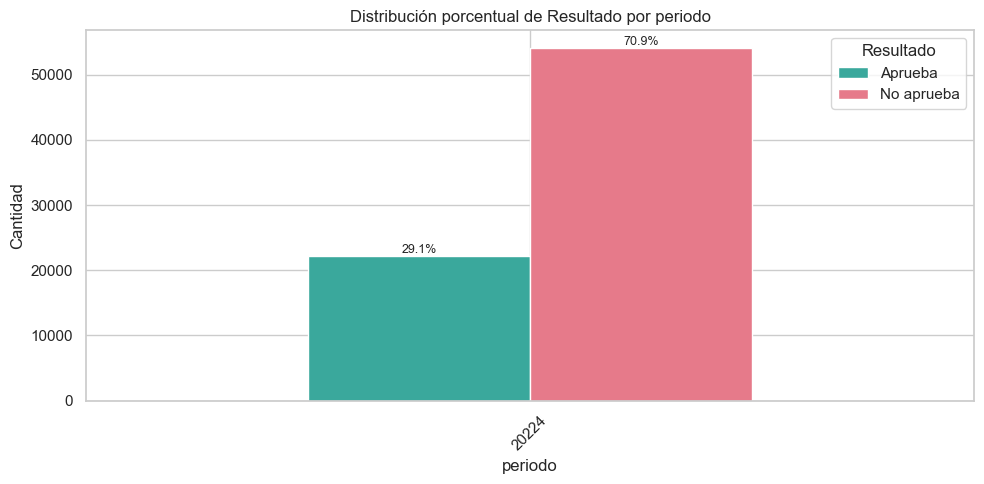

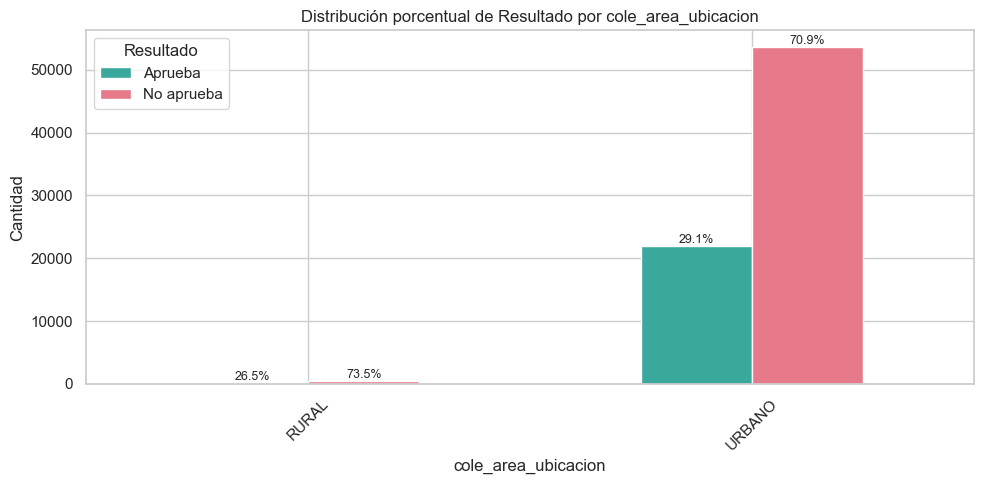

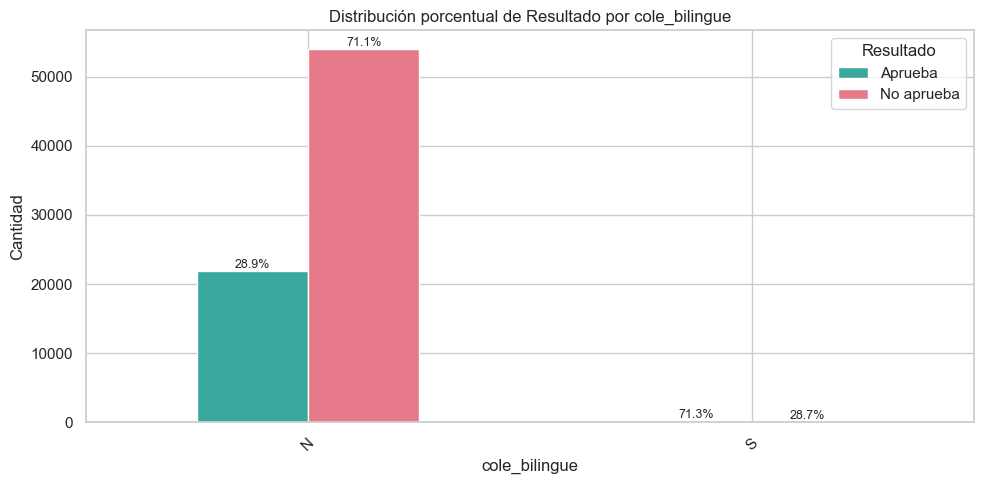

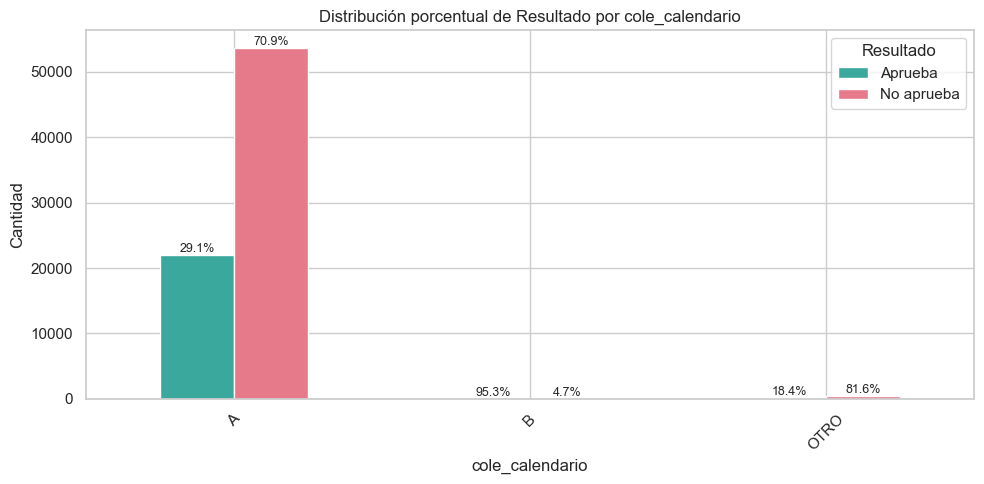

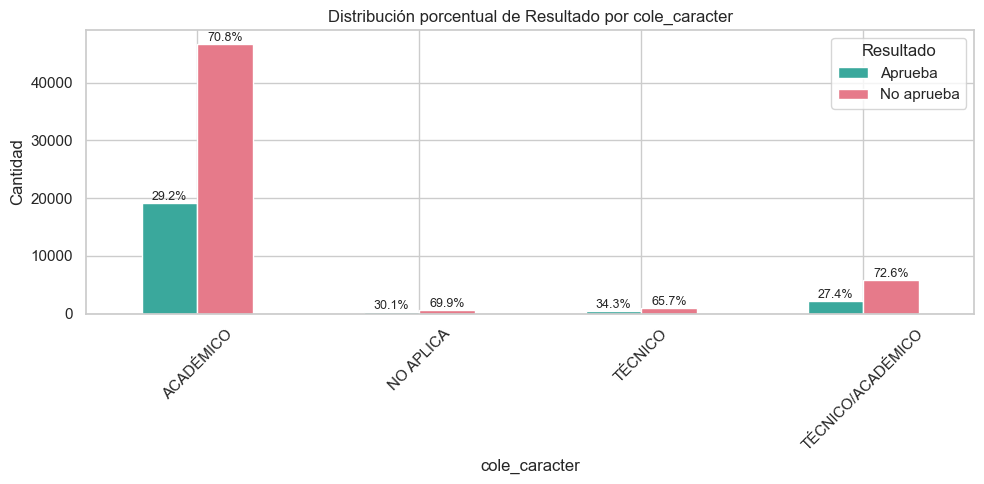

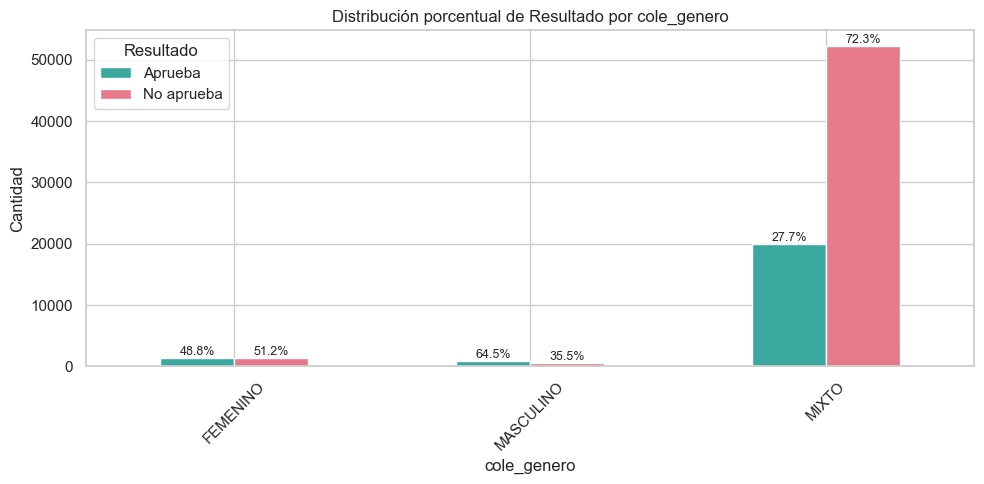

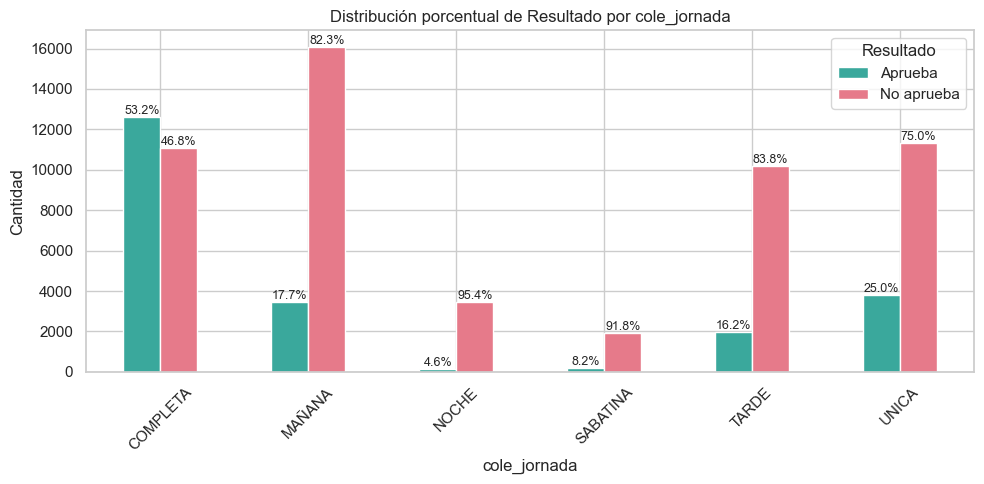

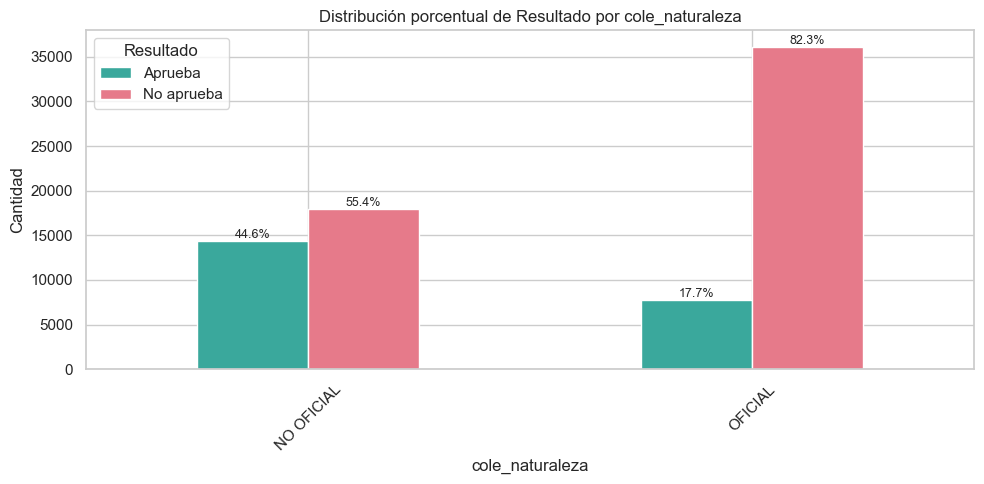

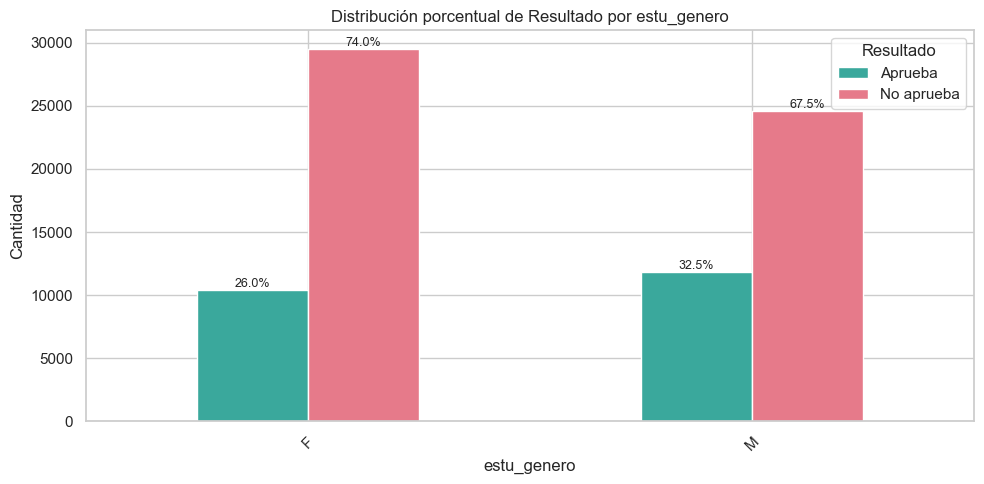

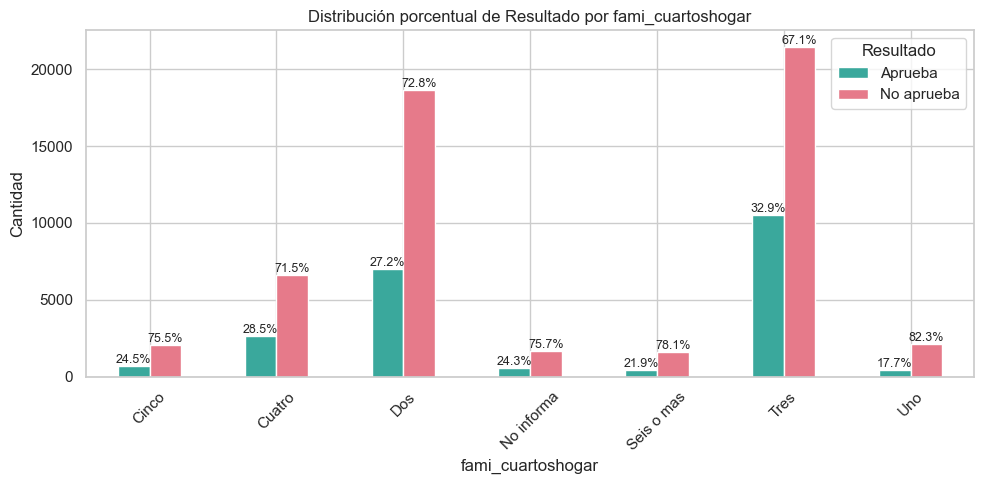

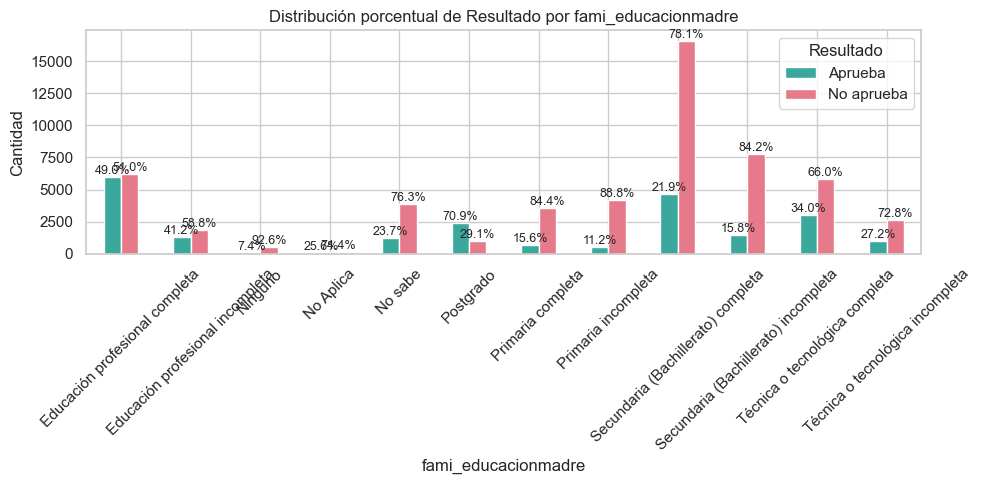

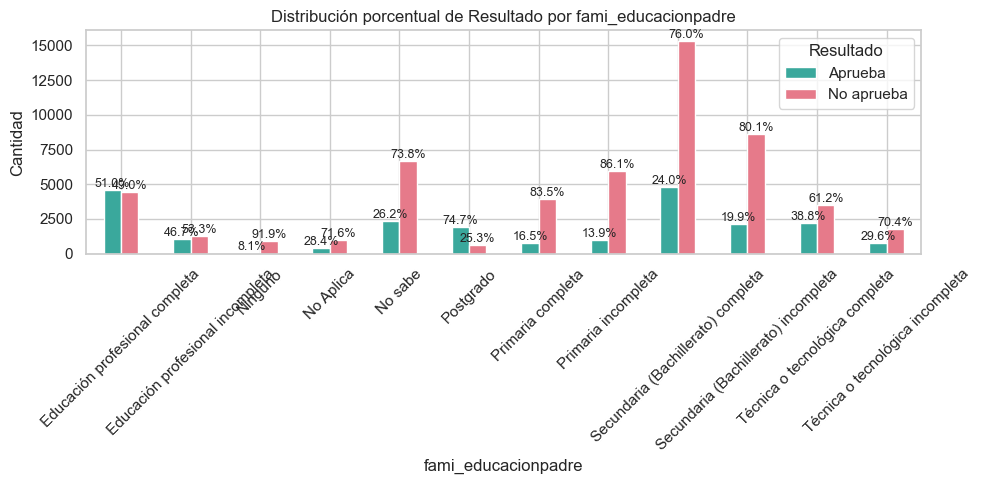

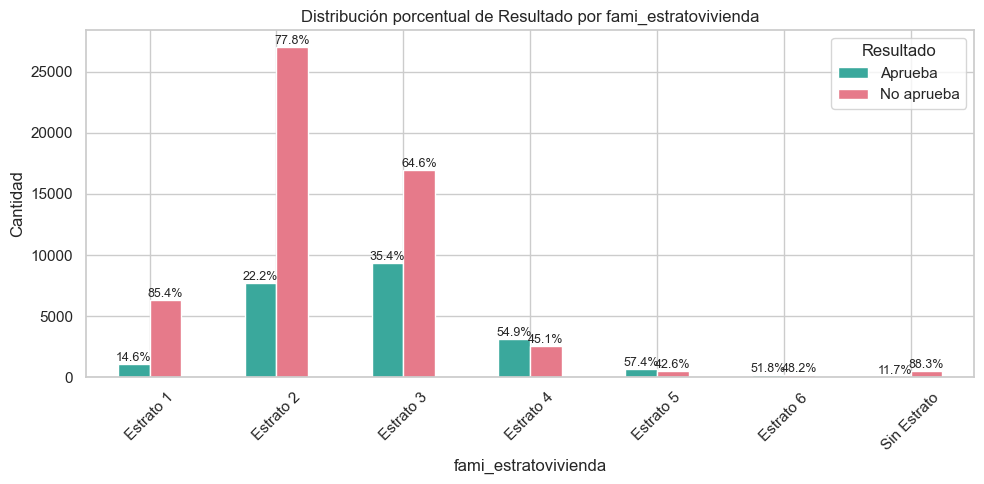

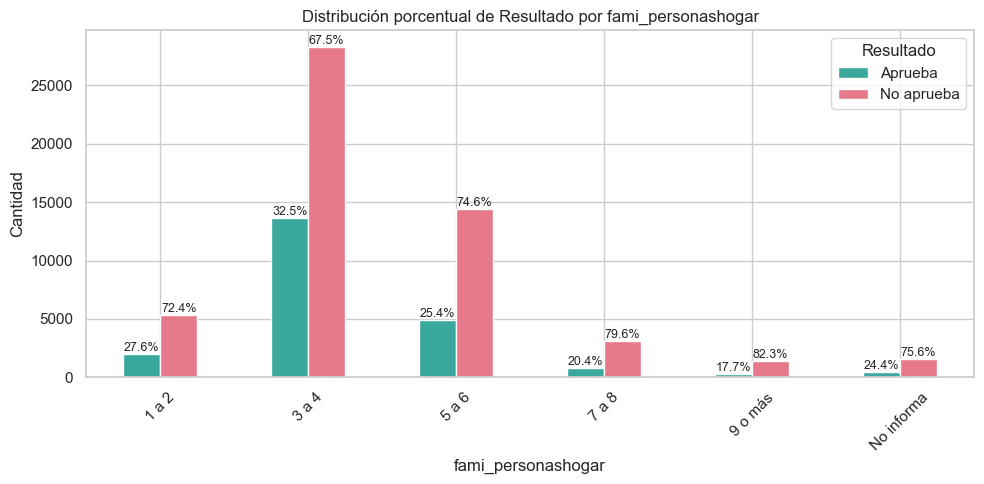

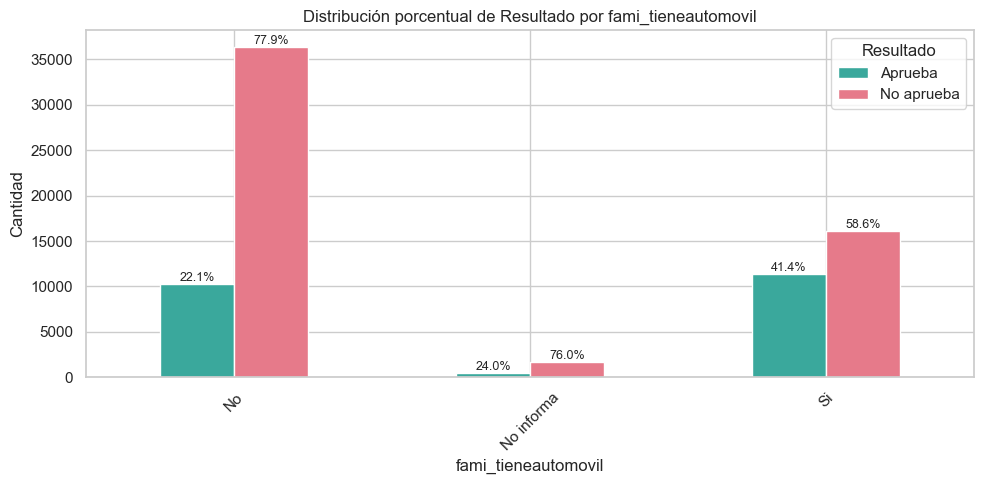

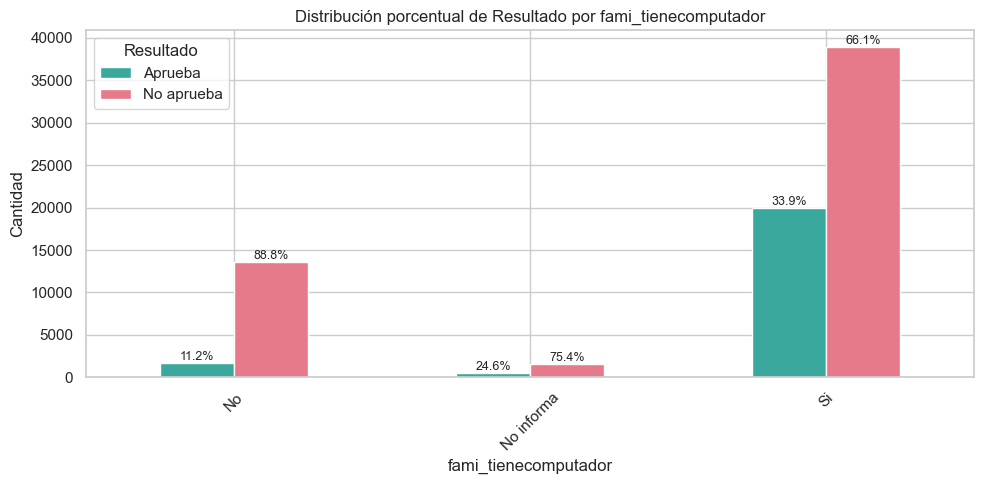

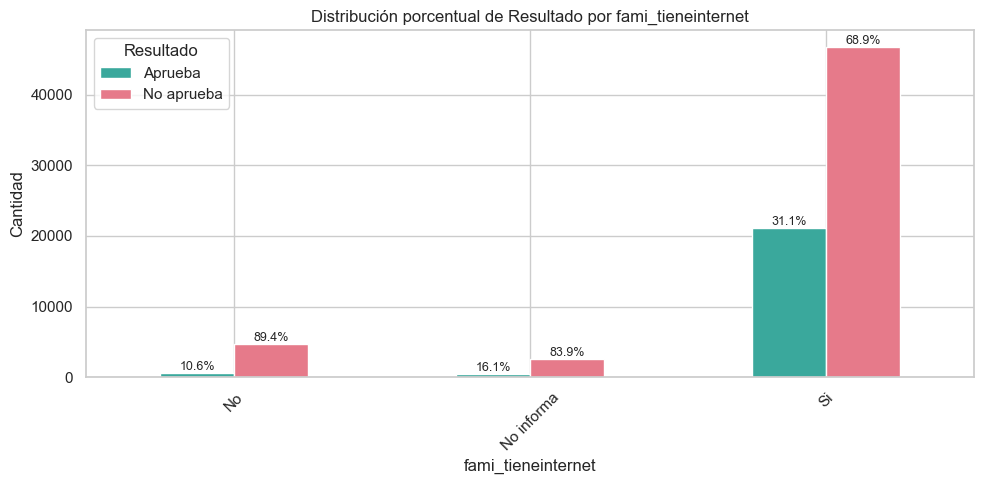

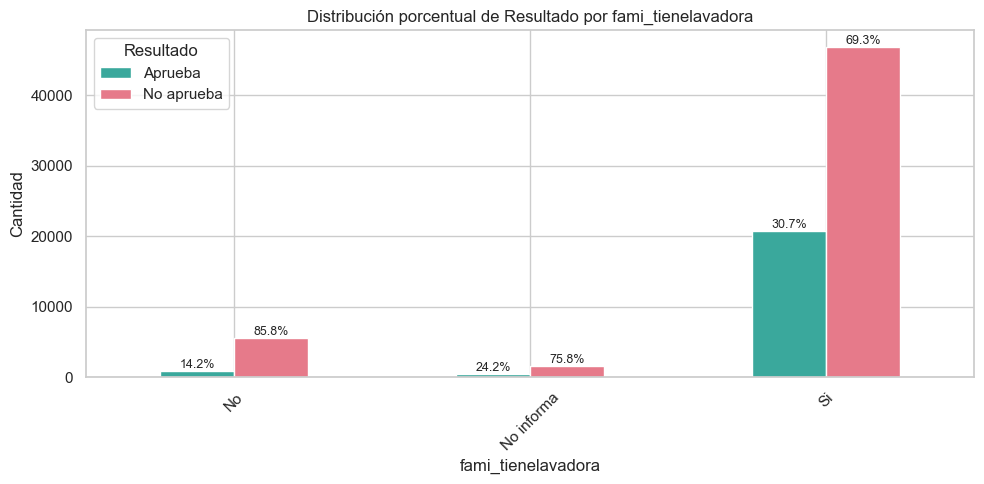

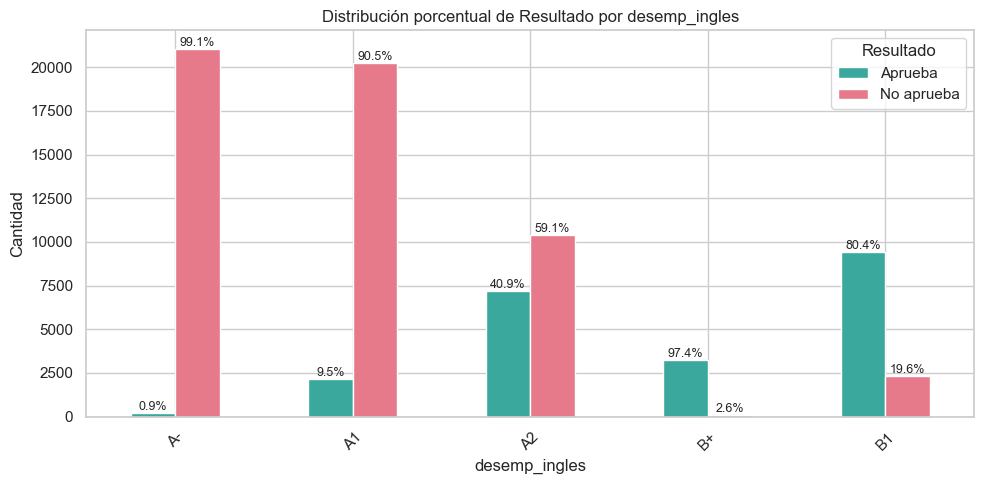

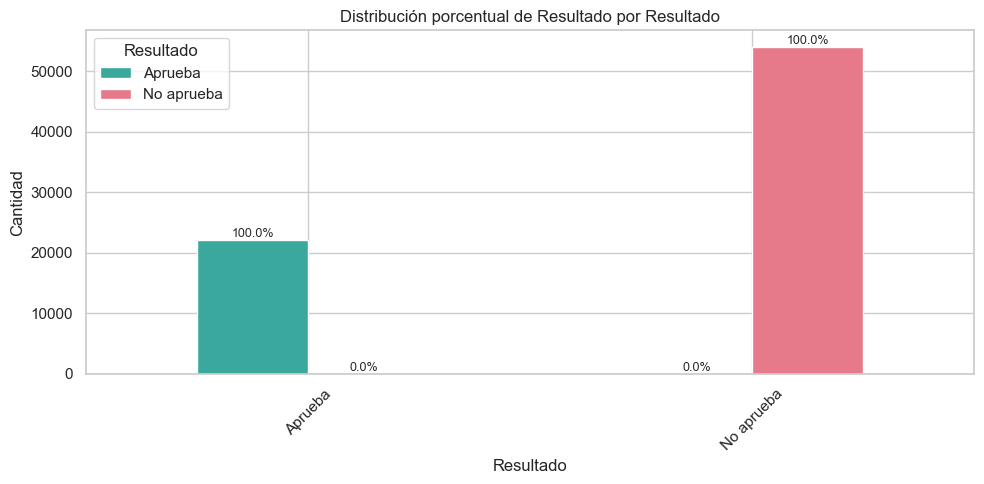

In [32]:
categoricos = dffinal.select_dtypes(include=["object", "category", "bool"])
def graficar_barras_manual(dffinal, variables, resultado="Resultado"):

    for var in variables:
        conteo = pd.crosstab(dffinal[var], dffinal[resultado])
        porcentaje = conteo.div(conteo.sum(axis=1), axis=0) * 100

        ax = conteo.plot(kind="bar", figsize=(10,5), color=["#3aa89c", "#e67a8a"])

        for i, categoria in enumerate(conteo.index):
            for j, col in enumerate(conteo.columns):

                valor = conteo.loc[categoria, col]
                pct = porcentaje.loc[categoria, col]

                ax.text(
                    i + (j-0.5)*0.25,
                    valor,
                    f"{pct:.1f}%",
                    ha="center",
                    va="bottom",
                    fontsize=9
                )

        plt.title(f"Distribución porcentual de {resultado} por {var}")
        plt.xlabel(var)
        plt.ylabel("Cantidad")
        plt.xticks(rotation=45)
        plt.legend(title=resultado)
        plt.tight_layout()
        plt.show()
graficar_barras_manual (dffinal, categoricos, resultado="Resultado")